# Анализ лояльности пользователей Яндекс Афиши

- Автор: Семенычев Никита Дмитриевич
- Дата: 08.11.2026

### Цели и задачи проекта

**Цель**: Изучить поведение пользователей для увеличения доли постоянных клиентов.

**Задачи**:
 - Загрузить данные и познакомиться с содержимым.
 - Провести предобработку данных.
 - Создать профиль пользователя
 - Провести исследовательский анализ данных, а именно провести:
    - Исследование признаков первого заказа и их связи с возвращением на платформу
    - Исследование поведения пользователей через показатели выручки и состава заказа
    - Исследование временных характеристик первого заказа и их влияния на повторные покупки
    - Корреляционный анализ количества покупок и признаков пользователя
 - Сформировать вывод и рекомендации по проведенному анализу.



### Описание данных

Для анализа поступили данные о заказах билетов на мероприятия и связанных с ними сущностях. Данные хранятся в реляционной базе данных (PostgreSQL) и распределены по нескольким таблицам.

#### Таблица `purchases`

Содержит информацию о заказах билетов:

- `order_id` — идентификатор заказа;
- `user_id` — идентификатор пользователя, совершившего заказ;
- `created_dt_msk` — дата создания заказа по московскому времени;
- `created_ts_msk` — дата и время создания заказа по московскому времени;
- `event_id` — идентификатор мероприятия из таблицы `events`;
- `cinema_circuit` — сеть кинотеатров, где проходит мероприятие. Если оно проходит не в кинотеатре, то здесь будет значение «нет»;
- `age_limit` — возрастное ограничение мероприятия;
- `currency_code` — валюта оплаты;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ (например, `mobile` — мобильные устройства, `desktop` — компьютеры);
- `revenue` — выручка от заказа;
- `service_name` — название билетного оператора;
- `tickets_count` — количество купленных билетов;
- `total` — общая сумма заказа.

#### Таблица `events`

Содержит данные о мероприятиях, доступных на платформе:

- `event_id` — идентификатор мероприятия;
- `event_name_code` — название мероприятия в закодированном виде;
- `event_type_description` — описание мероприятия;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `organizers` — организаторы мероприятия;
- `city_id` — идентификатор города проведения мероприятия из таблицы `city`;
- `venue_id` — идентификатор площадки проведения мероприятия из таблицы `venues`.

#### Таблица `venues`

Содержит сведения о площадках проведения мероприятий:

- `venue_id` — идентификатор площадки;
- `venue_name` — название площадки;
- `address` — адрес площадки.

#### Таблица `city`

Содержит список городов, относящихся к регионам:

- `city_id` — идентификатор города;
- `city_name` — название города;
- `region_id` — идентификатор региона, в котором расположен город, из таблицы `regions`.

### Таблица `regions`

Содержит список регионов, в которых проводятся мероприятия:

- `region_id` — идентификатор региона;
- `region_name` — название региона.
---

### Структура проекта

1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Создание профиля пользователя.
4. Исследовательский анализ данных.
5. Итоговые выводы.

## 1. Загрузка данных и знакомство с ними

In [1]:
# Импорт необходимых библиотек и функций
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy.pool import NullPool
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from phik import phik_matrix
from dotenv import load_dotenv
import os

In [2]:
# Эта строка читает файл .env из текущей папки и кладёт все пары ключ=значение в окружение
load_dotenv()

True

In [3]:
# формирование списка атрибутов для подключения
# значения будем доставать из виртуального окружения
db_config = {'user': os.getenv('user'),
             'pwd': os.getenv('pwd'),
             'host': os.getenv('host'),
             'port': int(os.getenv('port')),
             'db': os.getenv('db')
}

In [4]:
# формирование строки для подключения по предыдущим атрибутам
connection_string = 'postgresql+psycopg2://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)

In [5]:
# Создание объекта Engine, который внутри содержит пул соединений, который закрывается после использования
engine = create_engine(connection_string, poolclass=NullPool)

In [6]:
query = '''
SELECT
	user_id,
	device_type_canonical,
	order_id,
	created_dt_msk AS order_dt,
	created_ts_msk AS order_ts,
	currency_code,
	revenue,
	tickets_count,
  	EXTRACT(DAY FROM created_dt_msk - LAG(created_dt_msk) OVER(PARTITION BY user_id ORDER BY created_dt_msk)) AS days_since_prev,
  	event_id,
  	event_name_code AS event_name,
  	event_type_main,
  	service_name,
  	region_name,
  	city_name
FROM afisha.purchases p
JOIN afisha.events
    USING(event_id)
JOIN afisha.city
    USING(city_id)
JOIN afisha.regions
    USING(region_id)  
WHERE (p.device_type_canonical = 'mobile'
OR p.device_type_canonical = 'desktop')
AND event_type_main <> 'фильм'
ORDER BY user_id;
'''

In [7]:
df = pd.read_sql_query(query, con=engine)

In [8]:
df.head(20)

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк
5,000898990054619,mobile,2613713,2024-10-23,2024-10-23 15:12:00,rub,902.74,3,19.0,500862,9cc55c15-4375-4129-9979-3129688ba1b4,концерты,Облачко,Лугоградская область,Кристалевск
6,00096d1f542ab2b,desktop,6636941,2024-08-15,2024-08-15 16:48:48,rub,917.83,4,NaN,201953,2f98d69f-4e60-4ffc-8f16-e539383526b1,театр,Край билетов,Каменевский регион,Глиногорск
7,000a55a418c128c,mobile,4657981,2024-09-29,2024-09-29 19:39:12,rub,47.78,1,NaN,265857,0d876e01-851e-458b-ba61-753e0e0c4063,театр,Лучшие билеты,Поленовский край,Дальнозолотск
8,000a55a418c128c,mobile,4657952,2024-10-15,2024-10-15 10:29:04,rub,74.84,2,16.0,271579,ddc795f8-7ef8-4eb0-b299-cb3e6ee24ba1,театр,Лучшие билеты,Поленовский край,Дальнозолотск
9,000cf0659a9f40f,mobile,6818017,2024-06-20,2024-06-20 10:35:26,rub,1421.91,4,NaN,516728,11be386f-7cb7-4aa1-a8e4-ba73a29c1af2,концерты,Лови билет!,Широковская область,Радужнополье


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  str           
 1   device_type_canonical  290611 non-null  str           
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[us]
 4   order_ts               290611 non-null  datetime64[us]
 5   currency_code          290611 non-null  str           
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  str           
 11  event_type_main        290611 non-null  str           
 12  service_name           290611 non-null  str           


Рассмотрим созданный dataframe по запросу query. В датасете представлены 15 столбцов с общим количеством строк 290 611.

**_Типы данных и их корректность_**:
- **Str**: Столбцы этого типа (8): user_id, device_type_canonical, currency_code, event_name, event_type_main, service_name, region_name, city_name. Для столбцов device_type_canonical, currency_code и event_type_main стоит поменять тип данных на category. Все остальные столбцы имеют корректный тип данных. 
- **float64**: Столбцы этого типа (2): revenue, days_since_prev. Данный тип корректный для этих столбцов.
- **int64**: Столбцы этого типа (3): order_id, tickets_count, event_id. Данный тип для этих столбцов корректный.
- **datetime64[us]**: Столбцы этого типа (2): order_ts, order_dt. Данный тип для этих столбцов корректный.

Также для оптимизации работы и уменьшения используемой памяти было принято решение уменьшить размерность типов данных для столбцов tickets_count и days_since_prev.
    
**_Пропуски в данных_**:
В датасете имеются столбцы с пропусками, а именно: days_since_prev. Пропуски в days_since_prev — это ожидаемый результат: у первого заказа пользователя нет предыдущего заказа. Заполнять их не нужно, так как это исказит логику расчёта.
    
**_Итог_**: Большинство данных представлено в корректном типе данных. Названия самих столбцов скорректированы на этапе формирования витрины данных.

---

## 2. Предобработка данных

- Изменены типы данных device_type_canonical, currency_code и event_type_main на category

In [10]:
columns = ['device_type_canonical', 'currency_code', 'event_type_main']

for column in columns:
    df[column] = df[column].astype('category')

Сокращена размерность данных для столбцов tickets_count и days_since_prev.

In [11]:
df['tickets_count'] = pd.to_numeric(df['tickets_count'], downcast='integer')
df['days_since_prev'] = pd.to_numeric(df['days_since_prev'], downcast='float')

In [12]:
# Проверка изменений типов данных
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  str           
 1   device_type_canonical  290611 non-null  category      
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[us]
 4   order_ts               290611 non-null  datetime64[us]
 5   currency_code          290611 non-null  category      
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int8          
 8   days_since_prev        268678 non-null  float32       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  str           
 11  event_type_main        290611 non-null  category      
 12  service_name           290611 non-null  str           


Типы данных столбцов `tickets_count`, `days_since_prev` были понижены до int8 и float32 соответственно , а типы данных device_type_canonical, currency_code и event_type_main изменены на category.

- Изучены пропущенные значения в столбце `days_since_prev` и посчитано их количество.

In [13]:
round(df['days_since_prev'].isna().mean() * 100,2)

np.float64(7.55)

Всего 7,55 % пропусков в столбце `days_since_prev`. Данные значения являются нормальными, их заполнение приведет к искажению логики. 

Проверка на неявные пропуски.

In [14]:
caps_list = ["N/A", "None", "null", "undefined", "неизвестно", "пропуск", "NULL", "unknown", "nan"]

df.isin(caps_list).sum()

user_id                  0
device_type_canonical    0
order_id                 0
order_dt                 0
order_ts                 0
currency_code            0
revenue                  0
tickets_count            0
days_since_prev          0
event_id                 0
event_name               0
event_type_main          0
service_name             0
region_name              0
city_name                0
dtype: int64

Неявные пропуски не обнаружены.

Проверка на дубликаты строк.

In [15]:
df.duplicated().sum()

np.int64(0)

Явных дубликатов не обнаружено.

In [16]:
df.duplicated(subset=['order_id', 'order_ts']).sum()

np.int64(0)

На этапе SQL-анализа данных было найдено несовпадение уникальных городов (352) и строк в таблице `city` (353), стоит проверить дубликаты.

In [17]:
df_grouped = df.groupby('city_name')['region_name'].nunique()
df_grouped[df_grouped>1]

city_name
Глинополье    2
Name: region_name, dtype: int64

В двух регионах встречается город с одним названием, что не является ошибкой.

In [18]:
columns = ['device_type_canonical', 'currency_code', 'event_type_main']

for column in columns:
    print(df[column].unique())

['mobile', 'desktop']
Categories (2, str): ['desktop', 'mobile']
['rub', 'kzt']
Categories (2, str): ['kzt', 'rub']
['театр', 'выставки', 'другое', 'стендап', 'концерты', 'спорт', 'ёлки']
Categories (7, str): ['выставки', 'другое', 'концерты', 'спорт', 'стендап', 'театр', 'ёлки']


Все категориальные данные представлены корректно. Дополнительной нормализации не требуется.

Следует обратить внимание, что валюта представлена **не только в рублях**. Для сравнения выручки было принято решение перевести все в рубли. Для перевода использовался датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год — final_tickets_tenge_df.csv. Значения в рублях представлены для 100 тенге.

In [19]:
tenge_to_rub = pd.read_csv('final_tickets_tenge_df.csv')

In [20]:
tenge_to_rub.head(10)

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt
5,2024-01-15,100,19.4501,kzt
6,2024-01-16,100,19.4264,kzt
7,2024-01-17,100,19.4177,kzt
8,2024-01-18,100,19.5798,kzt
9,2024-01-19,100,19.5741,kzt


In [21]:
tenge_to_rub.info()

<class 'pandas.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    str    
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    str    
dtypes: float64(1), int64(1), str(2)
memory usage: 11.3 KB


Для корректного перевода валюты, стоит привести столбец data к datetime.

In [22]:
tenge_to_rub['data'] = pd.to_datetime(tenge_to_rub['data'])

# Проверка измененного типа
tenge_to_rub.info()

<class 'pandas.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   data     357 non-null    datetime64[us]
 1   nominal  357 non-null    int64         
 2   curs     357 non-null    float64       
 3   cdx      357 non-null    str           
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 11.3 KB


In [23]:
df_tenge_to_rub = pd.merge(
    df,
    tenge_to_rub,
    how='left',
    left_on='order_dt',
    right_on='data'
)

# Проверка
df_tenge_to_rub.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 19 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  str           
 1   device_type_canonical  290611 non-null  category      
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[us]
 4   order_ts               290611 non-null  datetime64[us]
 5   currency_code          290611 non-null  category      
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int8          
 8   days_since_prev        268678 non-null  float32       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  str           
 11  event_type_main        290611 non-null  category      
 12  service_name           290611 non-null  str           


In [24]:
df['revenue_rub'] = np.where(
    df_tenge_to_rub['currency_code'] == 'kzt',
    df_tenge_to_rub['revenue'] * df_tenge_to_rub['curs'] / 100,
    df_tenge_to_rub['revenue']
)

Был создан новый столбец `revenue_rub`, где вся выручка представлена в рублях.

In [25]:
# Проверка
df[['order_dt', 'currency_code', 'revenue',  'revenue_rub']].sort_values(by='currency_code')

,order_dt,currency_code,revenue,revenue_rub
270186,2024-06-03,kzt,3698.83,750.022856
140286,2024-09-27,kzt,164.39,31.769354
140287,2024-09-28,kzt,223.90,43.378610
140288,2024-09-28,kzt,328.77,63.696229
140289,2024-10-04,kzt,439.93,86.511355
...,...,...,...,...
97579,2024-07-30,rub,678.76,678.760000
97578,2024-07-03,rub,837.46,837.460000
97577,2024-07-03,rub,1256.19,1256.190000
97583,2024-09-24,rub,338.09,338.090000


In [26]:
(df['revenue_rub'].isna()).sum()

np.int64(0)

Пропуски в созданной колонке отсутствуют.

---
Проверим **выбросы** в численных данных, а именно в колонках: `revenue_rub`, `tickets_count`, `days_since_prev`.

На этапе исследовательского анализа с помощью SQL было выявлено:
- Некоторые типы событий имеют отрицательную или нулевую выручку:
	- концерт: -5.7
	- театр: 0.0
	- другое: -17.94
	- спорт: -90.76
	- спорт: -8.53
	- выставки: -6.33

На этапе исследовательского анализа с помощью SQL было выявлено, что **отрицательная выручка есть у 0.13% заказов, а нулевая — у 2%**.

In [27]:
df[['revenue_rub', 'tickets_count', 'days_since_prev']].describe(percentiles=[0.01, 0.5, 0.95, 0.99])

,revenue_rub,tickets_count,days_since_prev
count,290611.000000,290611.000000,268678.000000
mean,555.571987,2.754311,3.222381
std,875.498172,1.170620,11.350510
min,-90.760000,1.000000,0.000000
1%,0.000000,1.000000,0.000000
50%,351.140000,3.000000,0.000000
95%,1630.650000,5.000000,18.000000
99%,2628.421739,6.000000,63.000000
max,81174.540000,57.000000,148.000000


С помощью процентилей стало ясно, что в данных имеются аномально большие значения. Также, как и говорилось ранее, имеется отрицательная выручка.
Рассмотрим сначала диаграммы с выбросами.

Рассмотрим показатель `revenue_rub`.

<Axes: xlabel='revenue_rub'>

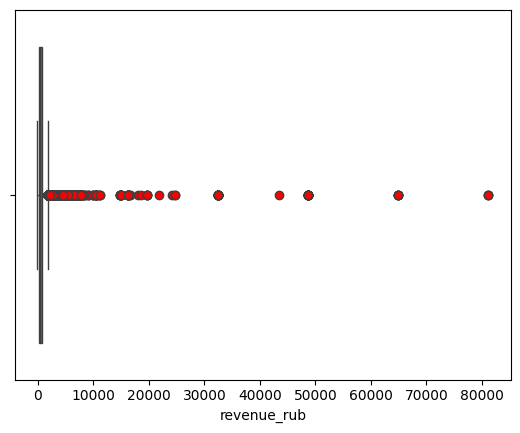

In [28]:
sns.boxplot(
    data=df,
    x='revenue_rub',
    flierprops={'markerfacecolor': 'red'}
)

На диаграмме много выбросов, и сама коробка (межквартильный размах) становится плохо различимой. Поэтому для визуального анализа дополнительно построена диаграмма с фильтрацией по 99-му перцентилю. Избавимся от части выбросов и посмотрим на диаграмму без них.

<Axes: xlabel='revenue_rub'>

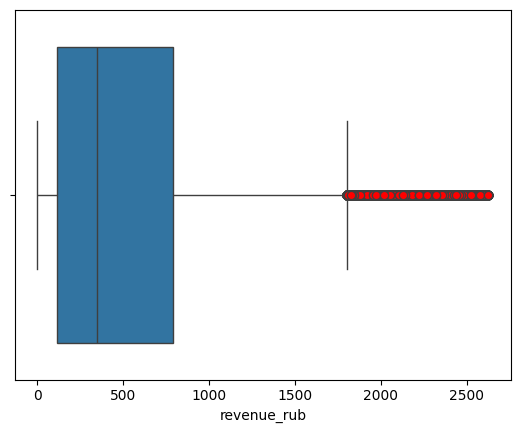

In [29]:
outliers = df['revenue_rub'].quantile(0.99)

sns.boxplot(
    data=df[(df['revenue_rub'] >= 0) & (df['revenue_rub'] < outliers)],
    x='revenue_rub',
    flierprops={'markerfacecolor': 'red'}
)

Как мы видим из диаграммы размаха, распределение имеет правостороннюю (положительную) асимметрию. Медиана ближе к первому квартилю (Q1), значит, большинство значений сосредоточено в нижней части распределения, а редкие большие значения вытягивают правый хвост к Q3 и дальше. Межквартальных размах составляет около 650, половина значений лежит в диапазоне от 100 до 750. 

Рассмотрим показатель `tickets_count`.

<Axes: xlabel='tickets_count'>

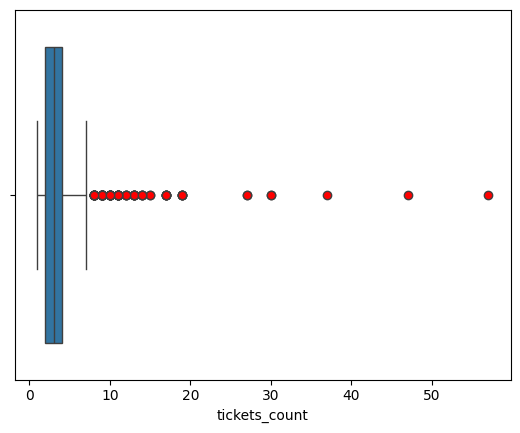

In [30]:
sns.boxplot(
    data=df,
    x='tickets_count',
    flierprops={'markerfacecolor': 'red'}
)

Рассмотрим диаграмму размаха с фильтрацией.

<Axes: xlabel='tickets_count'>

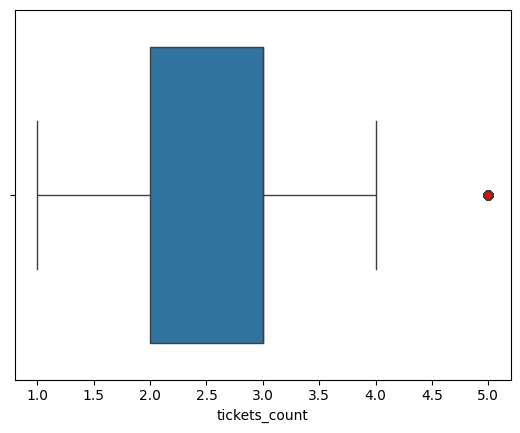

In [31]:
outliers = df['tickets_count'].quantile(0.99)

sns.boxplot(
    data=df[(df['tickets_count'] >= 0) & (df['tickets_count'] < outliers)],
    x='tickets_count',
    flierprops={'markerfacecolor': 'red'}
)

Как мы видим, диаграмма показывает правостороннюю асимметрию, что видно из выбросов справа, которые формирует хвост. Медиана и Q3 равны 3. Это означает, что 25% заказов содержат ровно 3 билета, а значение 3 является самым типичным для покупателей. 

Рассмотрим показатель `days_since_prev`. Данный показатель имеет 7,55% пропусков, которые не будут отображаться на диаграмме.

<Axes: xlabel='days_since_prev'>

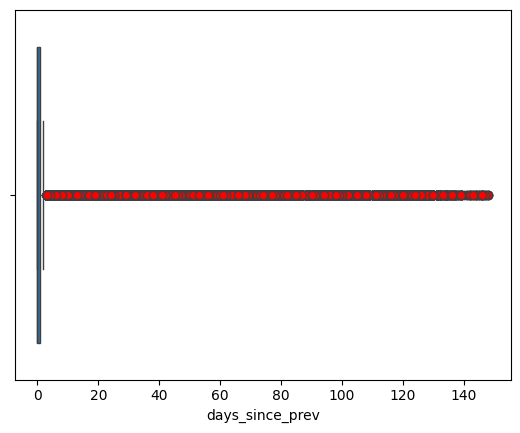

In [32]:
sns.boxplot(
    data=df,
    x='days_since_prev',
    flierprops={'markerfacecolor': 'red'}
)

Как и в предыдущих вариантах, стоит провести фильтрацию данных, чтобы построить различимую диаграмму.

<Axes: xlabel='days_since_prev'>

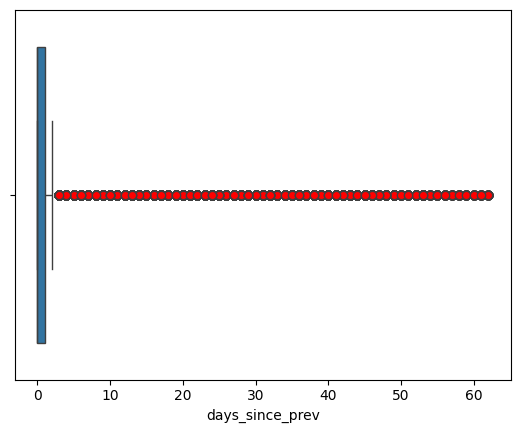

In [33]:
outliers = df['days_since_prev'].quantile(0.99)

sns.boxplot(
    data=df[(df['days_since_prev'] >= 0) & (df['days_since_prev'] < outliers)],
    x='days_since_prev',
    flierprops={'markerfacecolor': 'red'}
)

Коробка размаха все равно плохо различима, поэтому принято решение увеличить фильтрацию до 95-го перцентиля.

<Axes: xlabel='days_since_prev'>

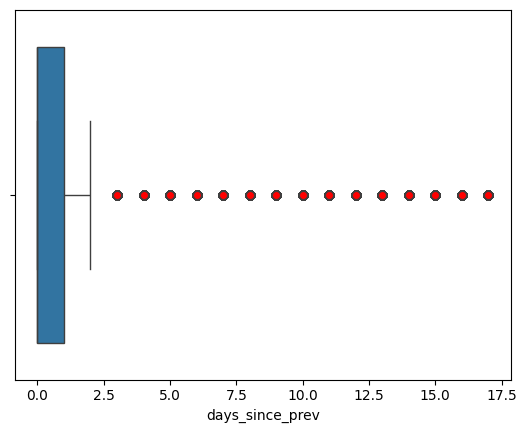

In [34]:
outliers = df['days_since_prev'].quantile(0.95)

sns.boxplot(
    data=df[df['days_since_prev'] < outliers],
    x='days_since_prev',
    flierprops={'markerfacecolor': 'red'}
)

Из диаграммы видна правосторонняя асимметрия, также минимум и медиана равны 0. Это означает, что 50% повторных покупок имеют 0 дней разницы между предыдущим заказом. Из чего следует, что пользователи часто покупают билеты на разные события или докупают на одно и то же событие в один день.

**Строки не удалялись**. Выбросы временно фильтровались только для визуализации.
Для дальнейшего анализа используются все данные, потому что:
- Отрицательные значения могут сигнализировать о возврате средств.
- Нулевые значения могут быть рассмотрены как бесплатные билеты
- Большие значения (выбросы) могут быть крупными заказами от особых клиентов.

---

### Промежуточный вывод

В результате предобработки данных были выполнены следующие действия:

__*Типы данных и память*__:
- Типы данных `device_type_canonical`, `currency_code` и `event_type_main` изменены на category для оптимизации памяти.
- Разрядность `tickets_count` и `days_since_prev` понижена до int8 и float32 соответственно.

__*Пропуски и дубликаты*__:

- Пропуски обнаружены только в days_since_prev (7,55%). Заполнять их не нужно, так как это исказит логику расчёта.
- Явных и неявных пропусков в остальных столбцах не обнаружено.
- Дубликатов по order_id и order_ts нет.

__*Новый столбец - `revenue_rub`*__: 

- Создан столбец revenue_rub — выручка, приведённая к рублю.
- Пропусков в revenue_rub нет (0). Для rub значения совпадают с revenue, для kzt — пересчитаны с делением на 100.

__*Выбросы и фильтрация*__:

- Обнаружены отрицательные значения revenue_rub (до -90.76) — возможно, возвраты.
- Обнаружены нулевые значения (мода = 0) — возможно, бесплатные билеты.
- Обнаружены экстремально большие значения (до 81 174 руб.) — это 1% выбросов.

Строки не удалялись. Выбросы временно фильтровались только для визуализации (фильтрация по 99-му и 95-му перцентилям внутри графиков).

Для дальнейшего анализа используются все данные, так как отрицательные значения могут сигнализировать о возвратах, нулевые — о бесплатных билетах, а крупные — о заказах от особых клиентов.

Также **половина повторных заказов сделана в тот же день** (0 дней разницы с предыдущим заказом), что говорит о склонности пользователей докупать билеты в один день.


---
## Создание профиля пользователя

Профиль будет построен по таким признакам, как:
- дата первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- билетный партнёр, к которому обращались при первом заказе;
- жанр первого посещённого мероприятия;
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее количество билетов в заказе;
- среднее время между заказами.
- бинарный признак is_two — совершил ли пользователь 2 и более заказа;
- бинарный признак is_five — совершил ли пользователь 5 и более заказов.

Перед формированием профиля пользователя нужно отсортировать датасет. Фильтровать отрицательные значения не стоит, это может исказить другие параметры, например, среднее значение заказов.

In [35]:
df.sort_values(by=['user_id', 'order_ts'], ascending=True, inplace=True)

user_profile = df.groupby('user_id').agg(
    first_order_data = ('order_ts', 'min'),
    last_order_data = ('order_ts', 'max'),
    first_device_type = ('device_type_canonical', 'first'),
    first_region = ('region_name', 'first'),
    first_service_name = ('service_name', 'first'),
    first_event_type_main = ('event_type_main', 'first'),
    total_orders = ('order_id', 'count'),
    avg_revenue_rub = ('revenue_rub', 'mean'),
    avg_count_tickets = ('tickets_count', 'mean'),
    time_between_orders = ('days_since_prev', 'mean')
)


user_profile['is_two'] = user_profile['total_orders'] >= 2
user_profile['is_five'] = user_profile['total_orders'] >= 5

user_profile

,first_order_data,last_order_data,first_device_type,first_region,first_service_name,first_event_type_main,total_orders,avg_revenue_rub,avg_count_tickets,time_between_orders,is_two,is_five
user_id,,,,,,,,,,,,
0002849b70a3ce2,2024-08-20 16:08:03,2024-08-20 16:08:03,mobile,Каменевский регион,Край билетов,театр,1,1521.940000,4.000000,NaN,False,False
0005ca5e93f2cf4,2024-07-23 18:36:24,2024-10-06 13:56:02,mobile,Каменевский регион,Мой билет,выставки,2,774.010000,3.000000,75.000,True,False
000898990054619,2024-07-13 19:40:48,2024-10-23 15:12:00,mobile,Североярская область,Лови билет!,другое,3,767.213333,2.666667,51.000,True,False
00096d1f542ab2b,2024-08-15 16:48:48,2024-08-15 16:48:48,desktop,Каменевский регион,Край билетов,театр,1,917.830000,4.000000,NaN,False,False
000a55a418c128c,2024-09-29 19:39:12,2024-10-15 10:29:04,mobile,Поленовский край,Лучшие билеты,театр,2,61.310000,1.500000,16.000,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
fff13b79bd47d7c,2024-07-16 22:17:10,2024-10-31 18:31:52,mobile,Каменевский регион,Мой билет,другое,9,688.043333,2.555556,13.375,True,True
fff32fc9ad0f9f6,2024-08-15 14:36:28,2024-10-28 23:40:38,desktop,Каменевский регион,Билеты без проблем,стендап,2,850.995000,2.500000,74.000,True,False
fffcd3dde79eb2c,2024-06-20 19:57:25,2024-10-30 13:37:43,desktop,Каменевский регион,Билеты без проблем,концерты,33,557.908485,2.787879,4.125,True,True


In [36]:
# Проверка 
user_profile.info()

<class 'pandas.DataFrame'>
Index: 21933 entries, 0002849b70a3ce2 to ffff00725179321
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   first_order_data       21933 non-null  datetime64[us]
 1   last_order_data        21933 non-null  datetime64[us]
 2   first_device_type      21933 non-null  category      
 3   first_region           21933 non-null  str           
 4   first_service_name     21933 non-null  str           
 5   first_event_type_main  21933 non-null  category      
 6   total_orders           21933 non-null  int64         
 7   avg_revenue_rub        21933 non-null  float64       
 8   avg_count_tickets      21933 non-null  float64       
 9   time_between_orders    13559 non-null  float32       
 10  is_two                 21933 non-null  bool          
 11  is_five                21933 non-null  bool          
dtypes: bool(2), category(2), datetime64[us](2), float32(

- Для пользователей с одним заказом среднее время между заказами не определено (NaN).
- Разница между общим числом уникальных пользователей в исходной таблице (22 000) и в сформированном датафрейме (21 933) обусловлена фильтрацией по типу устройства и исключением мероприятий типа "фильм".

---
Прежде чем проводить исследовательский анализ данных, стоит изучить сформированный профиль.

In [37]:
user_profile.describe(percentiles=[0.01,0.5, 0.99])

,first_order_data,last_order_data,total_orders,avg_revenue_rub,avg_count_tickets,time_between_orders
count,21933,21933,21933.000000,21933.000000,21933.000000,13559.000000
mean,2024-08-10 11:30:30.105913,2024-09-18 23:03:38.891943,13.249943,574.020929,2.755987,15.808537
min,2024-06-01 00:00:42,2024-06-01 01:29:40,1.000000,-10.770000,1.000000,0.000000
1%,2024-06-01 12:53:42.400000,2024-06-04 18:03:55.320000,1.000000,6.160000,1.000000,0.000000
50%,2024-08-08 21:24:01,2024-10-03 14:21:49,2.000000,475.224000,2.764151,8.000000
99%,2024-10-30 21:57:02.800000,2024-10-31 22:32:26.760000,152.000000,2282.473055,5.000000,112.000000
max,2024-10-31 23:55:27,2024-10-31 23:59:54,10251.000000,16738.696667,12.000000,148.000000
std,NaN,NaN,122.470535,557.647073,0.920739,22.249582


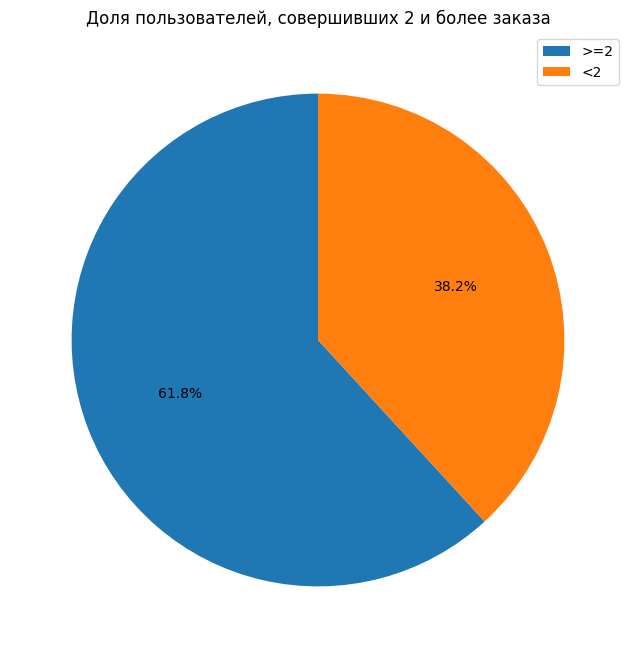

In [38]:
is_two_count = user_profile['is_two'].sum()

size = [
    is_two_count,
    user_profile.shape[0] - is_two_count
]
plt.figure(figsize=(12, 8))

plt.pie(
    size,
    startangle=90, 
    autopct='%1.1f%%',
)

plt.title('Доля пользователей, совершивших 2 и более заказа')
plt.legend(['>=2', '<2'])

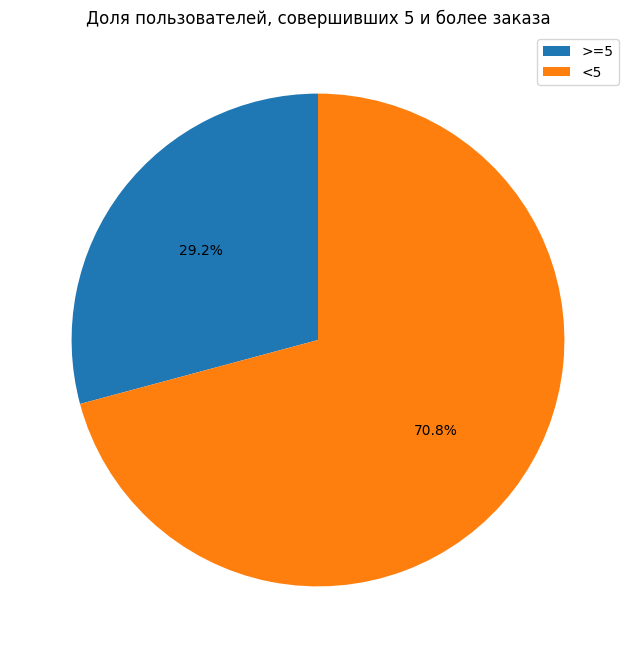

In [39]:
is_five_count = user_profile['is_five'].sum()

size = [
    is_five_count,
    user_profile.shape[0] - is_five_count
]

plt.figure(figsize=(12, 8))

plt.pie(
    size,
    startangle=90, 
    autopct='%1.1f%%',
)

plt.title('Доля пользователей, совершивших 5 и более заказа')
plt.legend(['>=5', '<5'])

---
### Промежуточный вывод

***В ходе анализа профилей пользователей было выявлено:***
- Общее число пользователей: 21 933.
- Доля пользователей с 2+ заказами: 61.8%
- Доля пользователей с 5+ заказами: 29.2%
- Доля пользователей с 1 заказом: 38.2%

Примечание: В категорию пользователей с 2+ заказами включены пользователи с 5+ заказами.

***По столбцу `avg_revenue_rub` определено:***
- Среднее: 574 руб.
- Медиана (50%): 475 руб.
- Максимум: 16 739 руб.
- 99-й перцентиль: 2 282 руб.
- Стандартное отклонение: 558 руб.
- Доля заказов с отрицательной выручкой: 0.13%.

Стандартное отклонение почти равно среднему, что свидетельствует о сильном разбросе, поэтому разница между максимумом и 99-м перцентилем составляет 14 457 руб.

***По столбцу `total_orders` определено:***
- Среднее: 13.25.
- Медиана: 2.
- 99-й перцентиль: 152.
- Максимум: 10 251.
- Стандартное отклонение: 122.5.

Разница между максимумом и 99-м перцентилем составляет 10 099 заказов.

***По столбцу `avg_count_tickets` определено:***
- Среднее: 2.76.
- Медиана (50%): 2.76.
- 99-й перцентиль: 5.
- Максимум: 12.
- Стандартное отклонение: 0.92.

Медиана и среднее значения совпали (с учётом округления), что может свидетельствовать о нормальном распределении данных.

***По столбцу `time_between_orders` определено:***
- Среднее: 15.8 дней.
- Медиана (50%): 8 дней.
- 99-й перцентиль: 112 дней.
- Максимум: 148 дней.
- Стандартное отклонение: 22.2 дня.
- Пропуски: 8 374 пользователя.

Данные пропуски корректны. Пропущенное значение указывает, что пользователь сделал всего одну покупку.

#### Итог: найдены аномальные значения в данных, а именно: 
- Отрицательная (0.13%) и нулевая выручка (2%) составляют 2,13% заказов
- Максимальное количество заказов на одного пользователя равно 10 251

Принято решение: 
- Оставить нулевые и отрицательные значения в выборке, так как они составляют всего 2.13% и, **возможно**, несут информацию о бесплатных билетах (промо) и возвратах
- Значение 10 251 является выбросом. Принято решение оставить его, чтобы не терять данные, но при визуализации графиков использовать фильтрацию по 99-му перцентилю, чтобы аномалия не искажала масштаб

---
## Исследовательский анализ данных

### Исследование признаков первого заказа и их связи с возвращением на платформу
---
В рамках исследования мы проверим **две продуктовые гипотезы**:

- ***Гипотеза 1:*** Тип мероприятия влияет на вероятность возврата: пользователи, начавшие со спортивных мероприятий, совершают повторный заказ чаще, чем те, кто начал с концертов.

- ***Гипотеза 2:*** В регионах с наибольшим числом пользователей доля повторных заказов выше, чем в менее активных регионах.

Проведем сегментацию пользователей:
- по типу их первого мероприятия;
- по типу устройства, с которого совершена первая покупка;
- по региону проведения мероприятия из первого заказа;
- по билетному оператору, продавшему билеты на первый заказ.

***Сегментация по типу первого мероприятия:***

Text(0.5, 0, 'Доля в %')

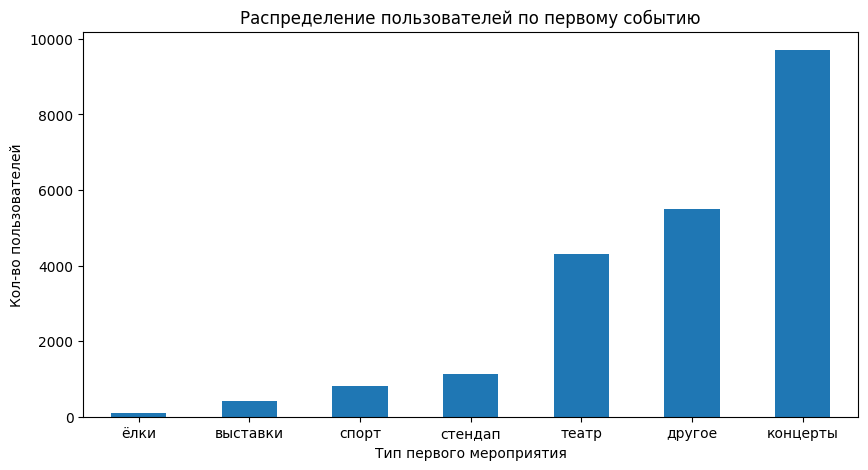

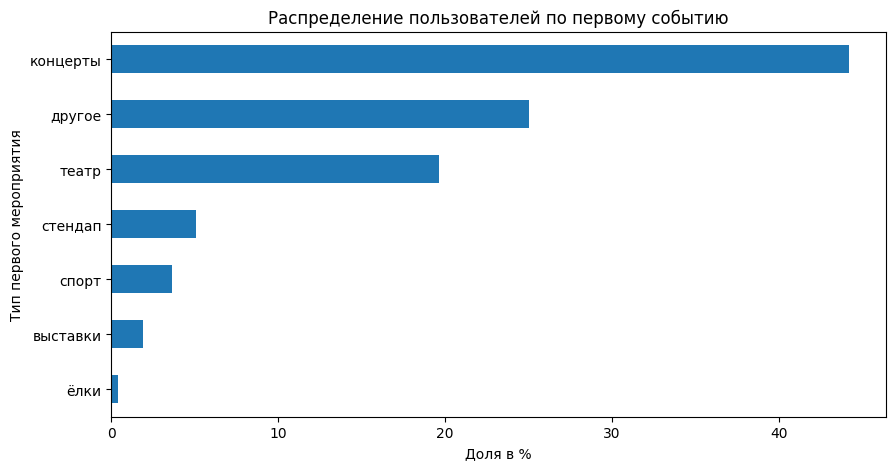

In [40]:
# сегментация пользователей по их первому мероприятию
user_grouped = user_profile.groupby('first_event_type_main').size().sort_values()

user_grouped.plot(
    kind='bar',
    title='Распределение пользователей по первому событию',
    ylabel='Кол-во пользователей',
    xlabel='Тип первого мероприятия',
    rot=0,
    figsize=(10,5)
)

plt.figure(figsize=(10,5))

user_share = round(user_grouped * 100 / user_profile.shape[0], 2)
user_share.plot(
    kind='barh'
    )
plt.title('Распределение пользователей по первому событию')
plt.ylabel('Тип первого мероприятия')
plt.xlabel('Доля в %')

In [41]:
user_share

first_event_type_main
ёлки         0.43
выставки     1.89
спорт        3.67
стендап      5.10
театр       19.66
другое      25.03
концерты    44.23
dtype: float64

Распределение сильно неравномерное, явные точки входа:
- концерты - 44% 
- другое - 25%
- театры - 20%

Меньше всего пользователей выбрали в качестве первого своего мероприятия в категориях:
- ёлки - 0.4%
- выставки - 1.9%

Найдем в каждом сегменте долю пользователей, которые совершили 2 и более заказов.

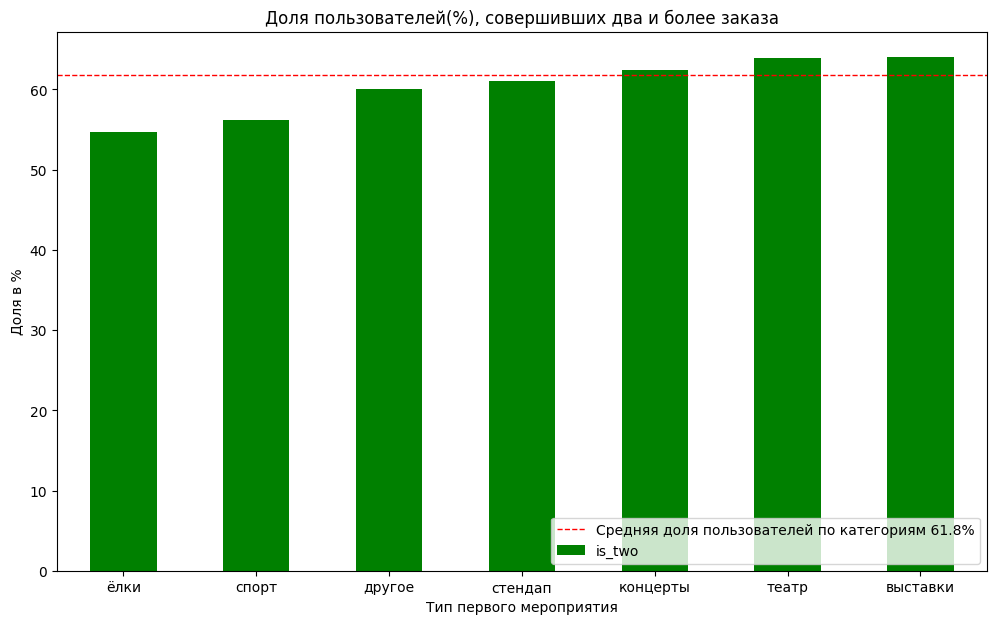

In [42]:
user_grouped_share = user_profile.groupby('first_event_type_main')['is_two'].mean().round(3)*100

user_grouped_share.sort_values().plot(
    kind='bar',
    color='green',
    title='Доля пользователей(%), совершивших два и более заказа',
    ylabel='Доля в %',
    xlabel='Тип первого мероприятия',
    rot=0,
    figsize=(12,7)
)

mean_share = user_profile['is_two'].mean().round(3) * 100

plt.axhline(mean_share, 
            color='red',
            linestyle='--',
            linewidth=1,
            label=f'Средняя доля пользователей по категориям {mean_share}%')

plt.legend(loc='lower right')

In [43]:
result = pd.concat([user_grouped_share, user_grouped], axis=1)
result.rename(columns={0: 'count_users'}, inplace=True)
result['abs_count'] = round(result['is_two'] / 100 * result['count_users'])

result.sort_values(by='count_users', ascending=False)

,is_two,count_users,abs_count
first_event_type_main,,,
концерты,62.4,9701,6053.0
другое,60.1,5489,3299.0
театр,63.9,4312,2755.0
стендап,61.0,1118,682.0
спорт,56.2,804,452.0
выставки,64.0,414,265.0
ёлки,54.7,95,52.0


Доли распределены более равномерно, лидерами являются:
- `выставки` - 64% при **414** пользователей
- `театр` - 63,9% при **4312**
- `концерты` - 62.4% - **9701**

Категория `выставки` лидирует по доле вернувшихся пользователей, но по абсолютному значению вернувшихся пользователей первое место занимает категория `концерты`: 6053, а выставки всего 265.

Средняя доля вернувшихся по всей выборке составляет 61.8%. Успешными точками входа (доля выше средней) являются `выставки`, `театр` и `концерты`. Категории стендап, другое, спорт и ёлки — ниже среднего.

***Продолжим сегментацию по типу устройства:***

Text(0.5, 1.0, 'Распределение пользователей по типу устройства')

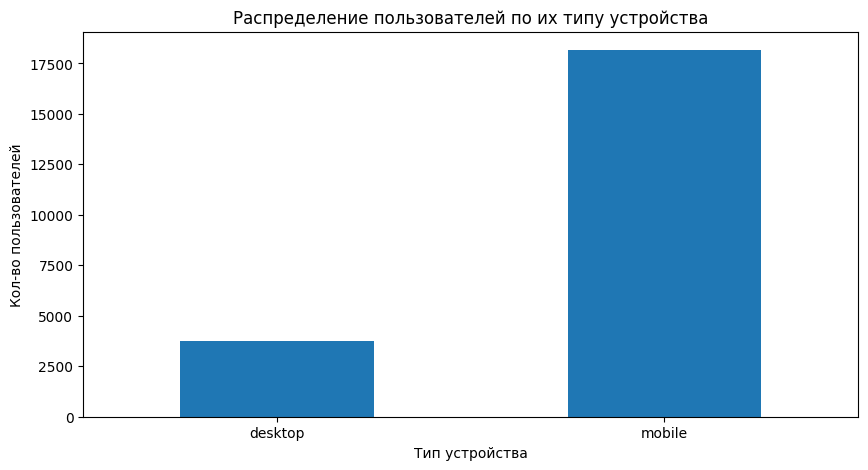

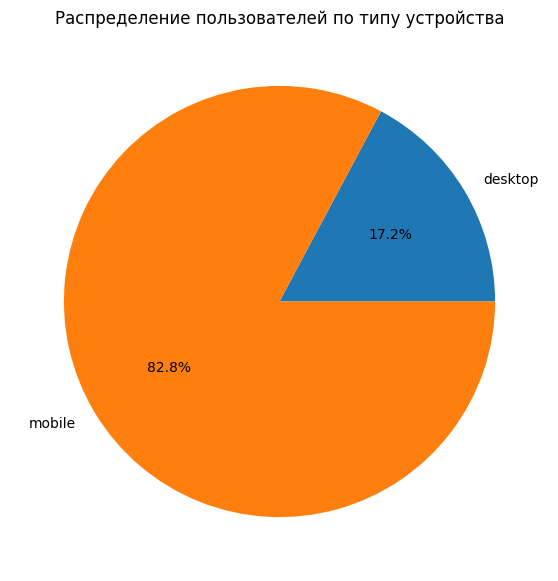

In [44]:
# сегментация пользователей по типу устройства, с которого совершенна первая покупка
user_grouped = user_profile.groupby('first_device_type').size().sort_values()

user_grouped.plot(
    kind='bar',
    title='Распределение пользователей по их типу устройства',
    ylabel='Кол-во пользователей',
    xlabel='Тип устройства',
    rot=0,
    figsize=(10,5)
)

plt.figure(figsize=(7,7))

user_grouped.plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Распределение пользователей по типу устройства')


Распределение сильно неравномерное, явная точка входа - тип устройства `mobile`. Пользователей с данным типом почти в 5 раз больше, чем людей использовавших компьютер для первого заказа.

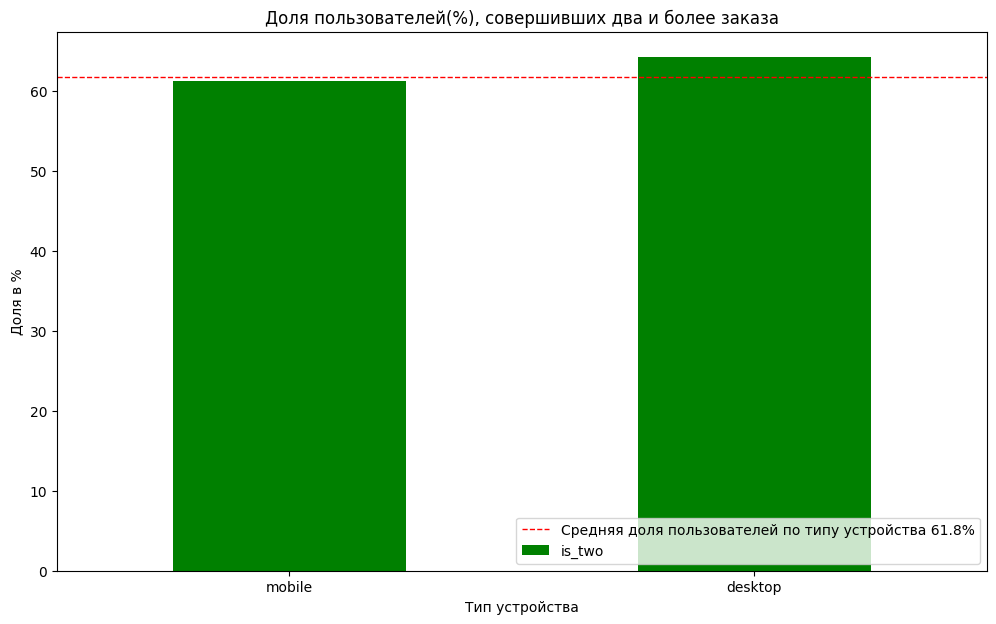

In [45]:
user_grouped_share = user_profile.groupby('first_device_type')['is_two'].mean().round(3)*100

user_grouped_share.sort_values().plot(
    kind='bar',
    color='green',
    title='Доля пользователей(%), совершивших два и более заказа',
    ylabel='Доля в %',
    xlabel='Тип устройства',
    rot=0,
    figsize=(12,7)
)

mean_share = user_profile['is_two'].mean().round(3) * 100

plt.axhline(mean_share, 
            color='red',
            linestyle='--',
            linewidth=1,
            label=f'Средняя доля пользователей по типу устройства {mean_share}%')

plt.legend(loc='lower right')

In [46]:
result = pd.concat([user_grouped_share, user_grouped], axis=1)
result.rename(columns={0: 'count_users'}, inplace=True)
result['abs_count'] = round(result['is_two'] / 100 * result['count_users'])

result.sort_values(by='count_users', ascending=False)

,is_two,count_users,abs_count
first_device_type,,,
mobile,61.3,18161,11133.0
desktop,64.2,3772,2422.0


Доля вернувшихся пользователей с desktop (64.2%) немного выше средней (61.8%), а с mobile (61.3%) — чуть ниже. Однако абсолютным лидером по числу вернувшихся пользователей является mobile (11 133  против 2 422). Это означает, что хотя конверсия в повторный заказ на компьютере выше, но  **основной объём лояльных и постоянных клиентов приходит с мобильных устройств**.

***Проведем сегментацию пользователей по региону, в котором был совершен их первый заказ***

In [47]:
# сегментация пользователей по региону, в котором был совершен первый заказ
user_grouped = user_profile.groupby('first_region').size().sort_values()
user_grouped

first_region
Верхозёрский край              1
Сосноводолинская область       1
Яснопольский округ             1
Залесский край                 2
Светолесский край              2
                            ... 
Малиновоярский округ         536
Озернинский край             679
Широковская область         1244
Североярская область        3795
Каменевский регион          7209
Length: 81, dtype: int64

Как мы видим, всего 81 регион, где были совершены заказы. Из-за большого количества регионов распределение сложно будет отобразить, поэтому стоит провести фильтрацию и исключить некоторые регионы из визуализации. Для распределения хватит 10 самых крупных по числу пользователей регионов.

In [48]:
user_grouped.describe()

count      81.000000
mean      270.777778
std       902.174401
min         1.000000
25%        22.000000
50%        53.000000
75%       214.000000
max      7209.000000
dtype: float64

Из описания серии видно, что распределение крайне неравномерное, при медианном значении в 53 и среднем 270, можно сказать, что в данных имеются выбросы, об этом также говорит стандартное отклонение в 902 единиц (пользователей).

In [49]:
user_grouped = user_grouped.iloc[-10:]
print('Топ-10 регионов по числу пользователей')
user_grouped

Топ-10 регионов по числу пользователей


first_region
Яблоневская область      419
Речиновская область      442
Светополянский округ     469
Травяная область         494
Шанырский регион         509
Малиновоярский округ     536
Озернинский край         679
Широковская область     1244
Североярская область    3795
Каменевский регион      7209
dtype: int64

<Axes: title={'center': 'Распределение пользователей по топ 10 регионам'}, xlabel='Доля в %', ylabel='Регион'>

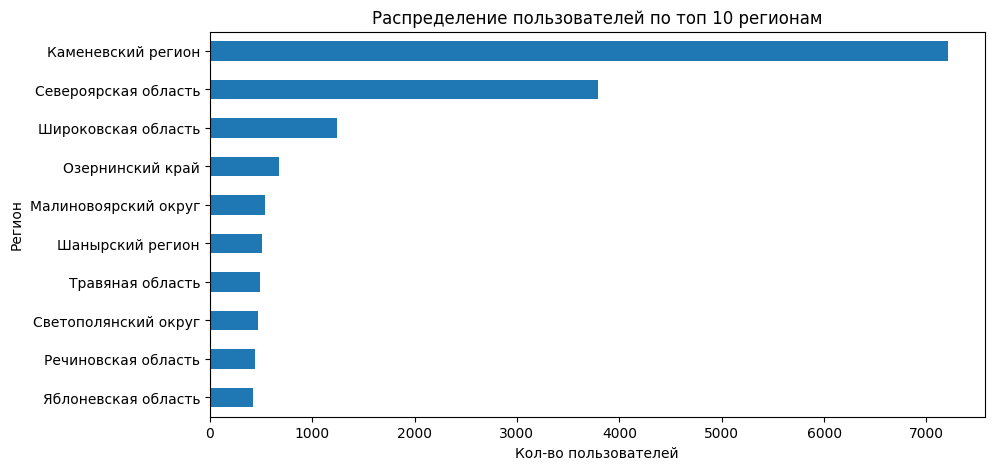

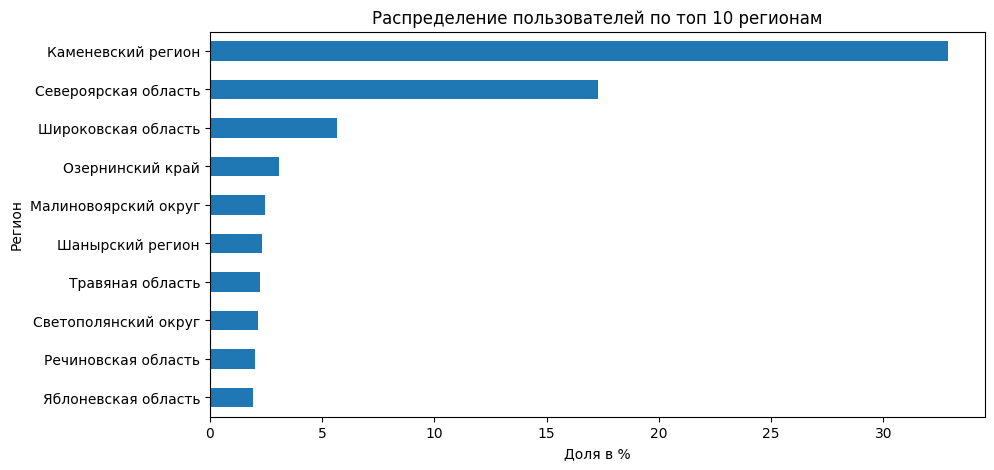

In [50]:
# сегментация пользователей по региону, из которого был совершен первый заказ
user_grouped.plot(
    kind='barh',
    title='Распределение пользователей по топ 10 регионам',
    ylabel='Регион',
    xlabel='Кол-во пользователей',
    figsize=(10,5)
)

plt.figure(figsize=(10,5))

user_share = round(user_grouped * 100 / user_profile.shape[0], 2)
user_share.plot(
    kind='barh',
    title='Распределение пользователей по топ 10 регионам',
    ylabel='Регион',
    xlabel='Доля в %',
    figsize=(10,5)
)

In [51]:
print(f'Топ-10 регионов покрывают {round(user_share.sum(),2)}% всех пользователей (остальные 71 регион: {round(100 - user_share.sum(),2)}%)')

Топ-10 регионов покрывают 72.02% всех пользователей (остальные 71 регион: 27.98%)


Точка входа - сегмент `Каменевский регион`, кол-во пользователей в данном регионе составляет 32.9% процентов (7209 пользователей). Потом идет `Североярская область` - 17,3% (3795) и `Широковская область` - 5,7% (1244). 

Если взять топ-10 регионов по доле возвратов, в них попадут регионы с 1–2 пользователями, где доля в 100% — это статистический шум. Поэтому для корректного анализа следует посчитать для 10 самых больших регионов по пользователям долю возвратов.

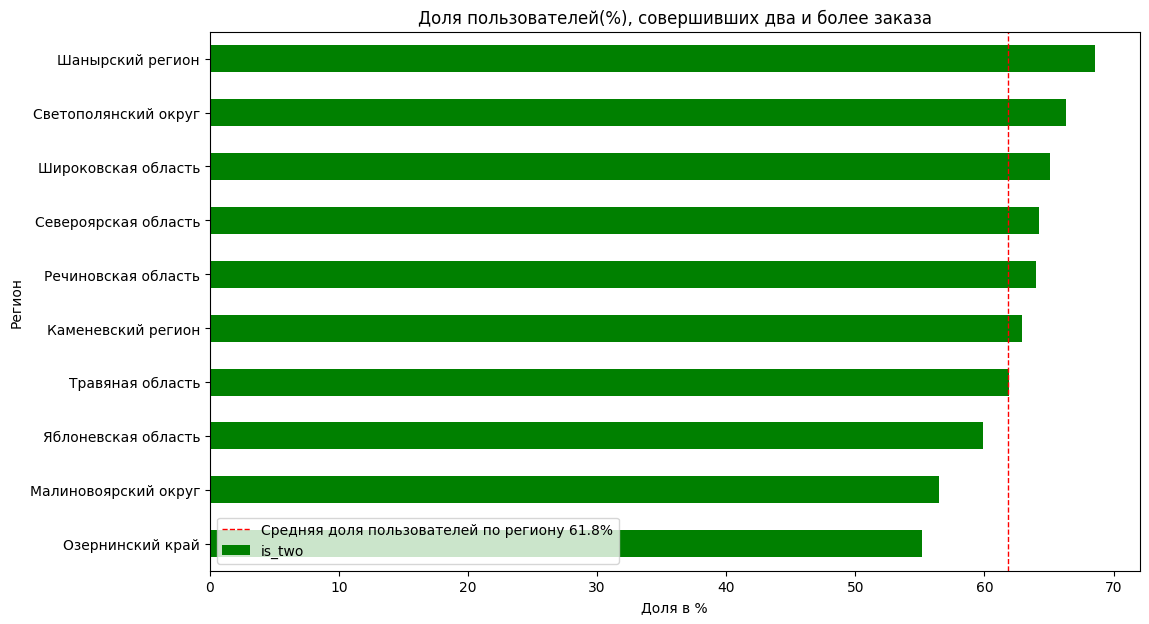

In [52]:
# Возьмем 10 крупнейших по числу пользователей регионов 
mask_for_10_regions = user_profile['first_region'].isin(user_share.index)
user_grouped_share = user_profile[mask_for_10_regions].groupby('first_region')['is_two'].mean().round(3)*100

user_grouped_share.sort_values().plot(
    kind='barh',
    color='green',
    title='Доля пользователей(%), совершивших два и более заказа',
    ylabel='Регион',
    xlabel='Доля в %',
    rot=0,
    figsize=(12,7)
)

mean_share = user_profile['is_two'].mean().round(3) * 100

plt.axvline(mean_share, 
            color='red',
            linestyle='--',
            linewidth=1,
            label=f'Средняя доля пользователей по региону {mean_share}%')

plt.legend(loc='lower left')


In [53]:
result = pd.concat([user_grouped_share, user_grouped], axis=1)
result.rename(columns={0: 'count_users'}, inplace=True)
result['abs_count'] = round(result['is_two'] / 100 * result['count_users'])

result.sort_values(by='count_users', ascending=False)

,is_two,count_users,abs_count
first_region,,,
Каменевский регион,62.9,7209,4534.0
Североярская область,64.2,3795,2436.0
Широковская область,65.1,1244,810.0
Озернинский край,55.2,679,375.0
Малиновоярский округ,56.5,536,303.0
Шанырский регион,68.6,509,349.0
Травяная область,61.9,494,306.0
Светополянский округ,66.3,469,311.0
Речиновская область,64.0,442,283.0


Среди 10 крупнейших регионов (на которые приходится 72% всех пользователей) есть как успешные точки входа, так и проблемные зоны.
- Лидер по доле возвратов — Шанырский регион (68.6%). Однако это сравнительно небольшой сегмент (509 пользователей)
- Абсолютный лидер по числу лояльных клиентов — Каменевский регион. Его доля возвратов (62.9%) чуть выше средней, но за счёт огромного размера (7209 пользователей) именно этот регион приносит 4534 вернувшихся клиента — больше, чем любой другой.

**Проблемные регионы**: Озернинский край (55.2%) и Малиновоярский округ (56.5%) — в них доля возвратов заметно ниже средней (61.8%). Это зоны, которые требуют дополнительного внимания маркетинга.



***Рассмотрим распределение пользователей по билетному оператору.***

In [54]:
# сегментация пользователей по билетному оператору
user_grouped = user_profile.groupby('first_service_name').size().sort_values()
user_grouped.describe()

count      34.000000
mean      645.088235
std      1184.185319
min         1.000000
25%        24.750000
50%       130.500000
75%       435.250000
max      5233.000000
dtype: float64

Распределение не является равномерным, есть аномально высокие значения. Кол-во в 34 оператора сложно будет визуализировать, для этого стоит провести фильтрацию и оставить только 10 самых крупных билетных операторов.

In [55]:
user_grouped = user_grouped.iloc[-10:]
print('Топ 10 оператор с наибольшим кол-вом пользователей')
user_grouped

Топ 10 оператор с наибольшим кол-вом пользователей


first_service_name
Дом культуры           355
Край билетов           462
Прачечная              592
Лучшие билеты         1186
Весь в билетах        1320
Облачко               2195
Билеты в руки         2587
Лови билет!           2853
Мой билет             3022
Билеты без проблем    5233
dtype: int64

<Axes: title={'center': 'Распределение пользователей по топ 10 билетным операторам'}, xlabel='Доля в %', ylabel='Оператор'>

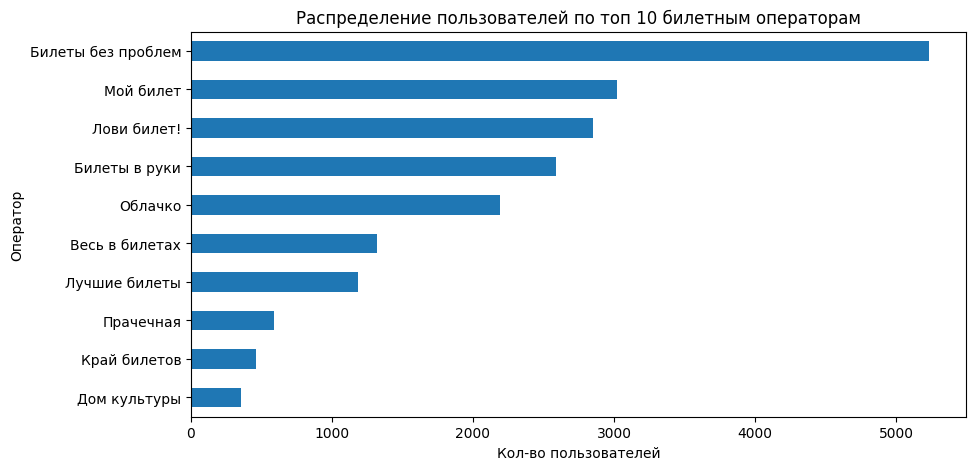

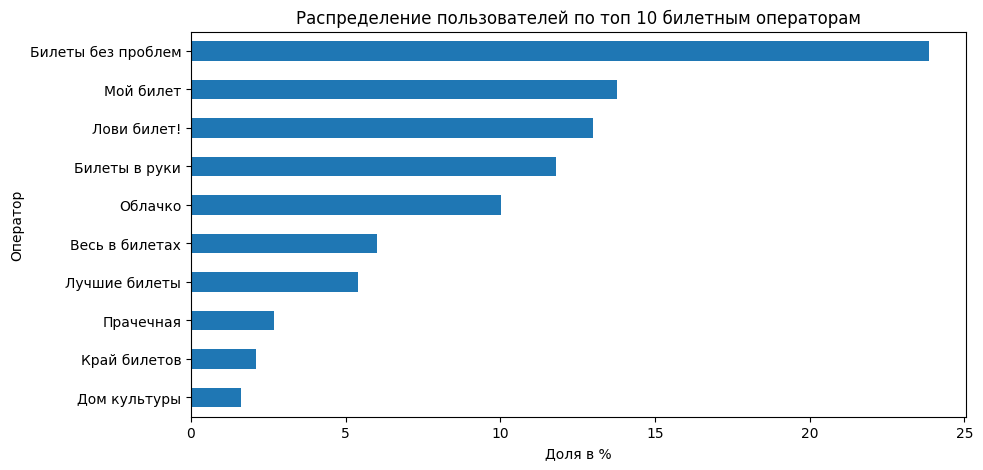

In [56]:
user_grouped.plot(
    kind='barh',
    title='Распределение пользователей по топ 10 билетным операторам',
    ylabel='Оператор',
    xlabel='Кол-во пользователей',
    figsize=(10,5)
)

plt.figure(figsize=(10,5))

user_share = round(user_grouped * 100 / user_profile.shape[0], 2)
user_share.plot(
    kind='barh',
    title='Распределение пользователей по топ 10 билетным операторам',
    ylabel='Оператор',
    xlabel='Доля в %',
    figsize=(10,5)
)

In [57]:
print(f'Топ-10 операторов покрывают {round(user_share.sum(),2)}% пользователей (остальные 24 — {round(100 - user_share.sum(),2)}%)')

Топ-10 операторов покрывают 90.32% пользователей (остальные 24 — 9.68%)


Наибольшие сегменты:
- Лови билет! - 13% (2853 пользователей)
- Мой билет - 14% (3022)
- Билеты без проблем - 23,9% (5233)

<!-- Если взять топ-10 билетных операторов по доле возвратов, в нем может быть также как и в ситуации с регионами - **статистический шум**, поэтому для корректного анализа следует посчитать для 10 самых больших по пользователям операторов долю возвратов. -->

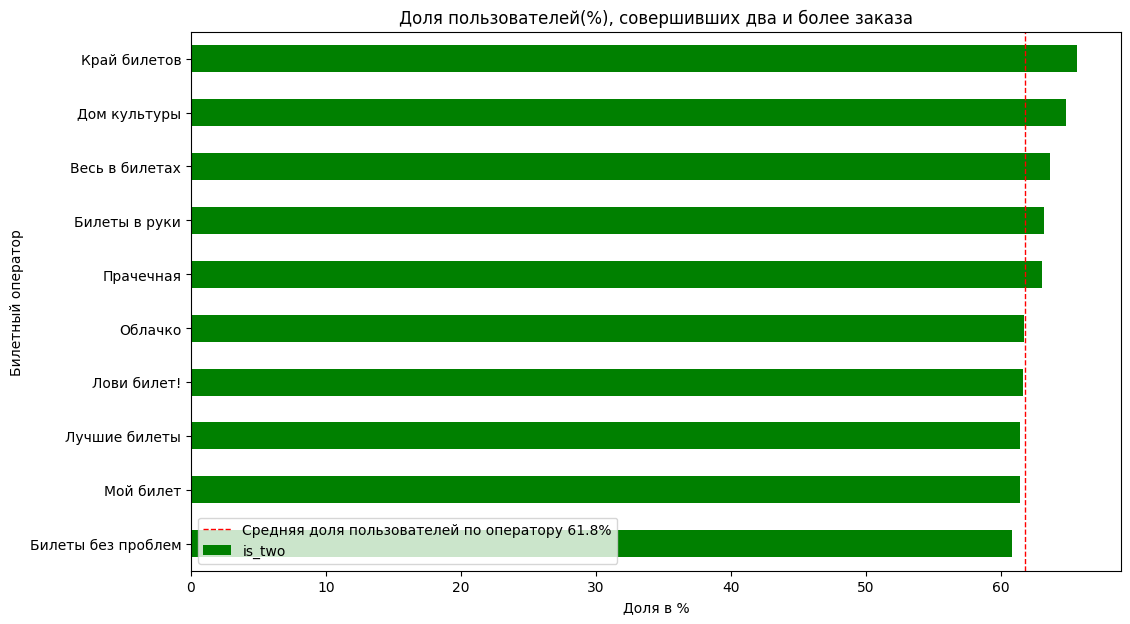

In [58]:
# Возьмем 10 крупнейших по числу пользователей билетных операторов
mask_for_10_operators = user_profile['first_service_name'].isin(user_share.index)
user_grouped_share = user_profile[mask_for_10_operators].groupby('first_service_name')['is_two'].mean().round(3)*100

user_grouped_share.sort_values().plot(
    kind='barh',
    color='green',
    title='Доля пользователей(%), совершивших два и более заказа', 
    ylabel='Билетный оператор',
    xlabel='Доля в %',
    rot=0,
    figsize=(12,7)
)

mean_share = user_profile['is_two'].mean().round(3) * 100

plt.axvline(mean_share, 
            color='red',
            linestyle='--',
            linewidth=1,
            label=f'Средняя доля пользователей по оператору {mean_share}%')

plt.legend(loc='lower left')


In [59]:
result = pd.concat([user_grouped_share, user_grouped], axis=1)
result.rename(columns={0: 'count_users'}, inplace=True)
result['abs_count'] = round(result['is_two'] / 100 * result['count_users'])

result.sort_values(by='count_users', ascending=False)

,is_two,count_users,abs_count
first_service_name,,,
Билеты без проблем,60.8,5233,3182.0
Мой билет,61.4,3022,1856.0
Лови билет!,61.6,2853,1757.0
Билеты в руки,63.2,2587,1635.0
Облачко,61.7,2195,1354.0
Весь в билетах,63.6,1320,840.0
Лучшие билеты,61.4,1186,728.0
Прачечная,63.0,592,373.0
Край билетов,65.6,462,303.0


Среди 10 крупнейших операторов (на которых приходится 90.3% всех пользователей):
- Лидер по доле возвратов — Край билетов (65.6%). Это выше средней доли по выборке (61.8%). Однако по абсолютному числу вернувшихся клиентов он занимает лишь предпоследнее место (303 человека), так как его общая аудитория мала (462 пользователя).
- Абсолютный лидер по объёму — Билеты без проблем. У него самая большая аудитория (5233 пользователя) и самое большое число вернувшихся (3182 человека). Но по доле возвратов он замыкает десятку (60.8%), находясь чуть ниже среднего уровня.
- Остальные крупные операторы (Мой билет, Лови билет!, Билеты в руки) показывают стабильную долю возвратов в диапазоне 61.4–63.2%, близкую к среднему значению.

Проверка выдвинутых гипотез:
1) ***Гипотеза 1 - Пользователи, начавшие со спорта, возвращаются чаще, чем начавшие с концертов***: гипотеза опровергнута. Доля вернувшихся со спорта составляет 56.2%, а с концертов — 62.4%. Спорт оказался одним из самых слабых сегментов.

2) ***Гипотеза 2 - В регионах с наибольшим числом пользователей доля повторных заказов выше, чем в менее активных:*** гипотеза подтверждается частично. В трёх крупнейших регионах (Каменевский, Североярская, Широковская) доля возвратов (62.9%, 64.2% и 65.1%) держится выше средней по выборке (61.8%). Однако абсолютным лидером по доле стал Шанырский регион (68.6%), который не входит в топ-5 по количеству пользователей. При этом некоторые небольшие регионы показывают результат ниже среднего, например, Яблоневская область.

---
### Промежуточный вывод

В ходе исследовательского анализа признаков первого заказа и их связи с возвращением на платформу было выявлено:

1. **Средняя доля возвратов** (средняя по выборке): **61.8%.**

2. ***Самые массовые сегменты:***
- _По типу события_: Концерты (44%), Другое (25%), Театр (20%).
- _По устройству_: Mobile (18 161 чел. — 83% всех пользователей).
- _По региону_: Каменевский регион (7209 чел. — 32.9%), Североярская обл. (3795 чел. — 17,3%). Топ-10 регионов покрывают 72% пользователей.
- _По оператору_: Билеты без проблем (5233 чел.), Мой билет (3022), Лови билет! (2853). Топ-10 операторов покрывают 90.3% пользователей.

3. ***Лидеры по удержанию*** (доля возвратов выше 61.8%):
- _По событию_: Выставки (64%), Театр (63.9%), Концерты (62.4%).
- _По устройству_: Desktop (64.2%).
- _По региону_: Шанырский (68.6%), Светополянский (66.3%), Широковская обл. (65.1%).
- _По оператору_: Край билетов (65.6%), Дом культуры (64.8%).

4. ***Аутсайдеры по удержанию*** (доля возвратов ниже 61.8%):
- _По событию_: Спорт (56.2%), Ёлки (54.7%).
- _По устройству_: Mobile (61.3%).
- _По региону_: Озернинский край (55.2%), Малиновоярский округ (56.5%).
- _По оператору_: Билеты без проблем (60.8%), Мой билет (61.4%).

Несмотря на то, что у Desktop доля возвратов выше, абсолютное число вернувшихся пользователей составляет 2422, а у Mobile — 11 133, потому что мобильных пользователей почти в 5 раз больше. То же самое с событиями: у Выставок доля 64%, но вернувшихся всего 265, а у Концертов доля 62.4%, но вернувшихся 6053. И с операторами: у оператора Билеты без проблем самая большая аудитория (5233) и больше всего вернувшихся (3182), хотя доля вернувшихся пользователей самая низкая среди топ-10 операторов — 60.8%, что на 1 п.п. ниже средней по выборке.

---
### Исследование поведения пользователей через показатели выручки и состава заказа

**Примечание**: в тексте задания 4.2.1 указано "выручка с билета", однако согласно заданию 3.1 метрика avg_revenue_rub рассчитывалась как средняя выручка с заказа. Для анализа используется именно она

Чтобы проследить связь между средней выручкой сервиса с заказа и повторными заказами, следует построить сравнительные гистограммы распределения средней выручки с заказа:
- для пользователей, совершивших один заказ;
- для вернувшихся пользователей, совершивших 2 и более заказа.

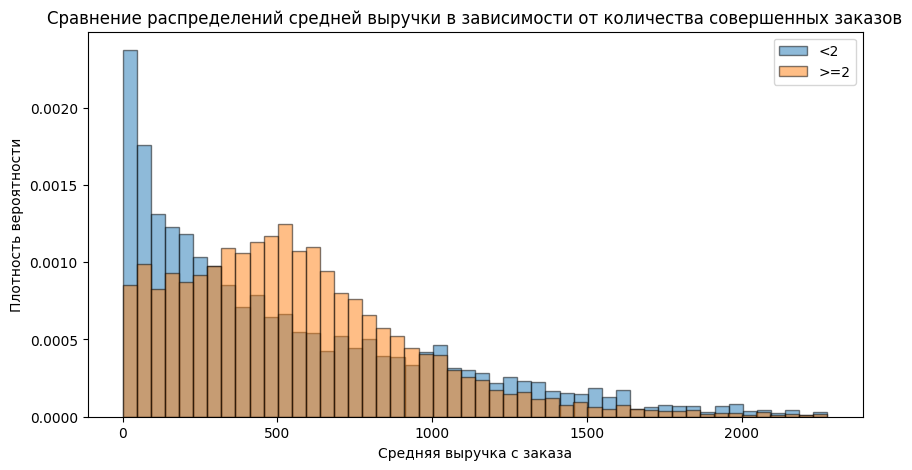

In [60]:
# Проводим фильтрацию по 99-му перцентилю 
filter_revenue = (user_profile['avg_revenue_rub'] <= user_profile['avg_revenue_rub'].quantile(0.99)) & (user_profile['avg_revenue_rub'] > 0)

filtered_profile = user_profile[filter_revenue]

plt.figure(figsize=(10,5))

for i in user_profile['is_two'].unique():
    filtered_profile.loc[filtered_profile['is_two'] == i, 'avg_revenue_rub'].plot(
        kind='hist',
        bins=50,
        alpha=0.5,
        edgecolor='black',
        density=True
    )

plt.title('Сравнение распределений средней выручки в зависимости от количества совершенных заказов')
plt.xlabel('Средняя выручка с заказа')
plt.ylabel('Плотность вероятности')
plt.legend(['<2', '>=2'])


Распределения существенно различаются:
- У пользователей, совершивших менее 2 заказов, средняя выручка сильно сконцентрирована в самом начале шкалы (преимущественно в диапазоне 0–45 руб.). В этой зоне наблюдается максимальная плотность вероятности (около 0.0023). Это говорит о том, что среди ушедших пользователей очень высока доля тех, кто купил самый дешевый билет и больше не вернулся. Далее распределение резко падает.
- У пользователей, совершивших 2 и более заказов, пик распределения смещен вправо — в диапазон примерно 365–635 руб. После этого диапазона также идет плавный спад.

Пользователи, совершившие 2+ заказа, имеют более высокий средний чек по всем своим заказам, чем пользователи с одним заказом. Среди не вернувшихся пользователей высока доля клиентов с очень дешёвым единственным заказом. 

***Примечание:*** На этом и последующем графиках не отображена нулевая и отрицательная выручка, чтобы было легче понять распределение выручки.

---
Далее сравним распределение по средней выручке с заказа в двух группах пользователей:
- совершившие 2–4 заказа;
- совершившие 5 и более заказов.

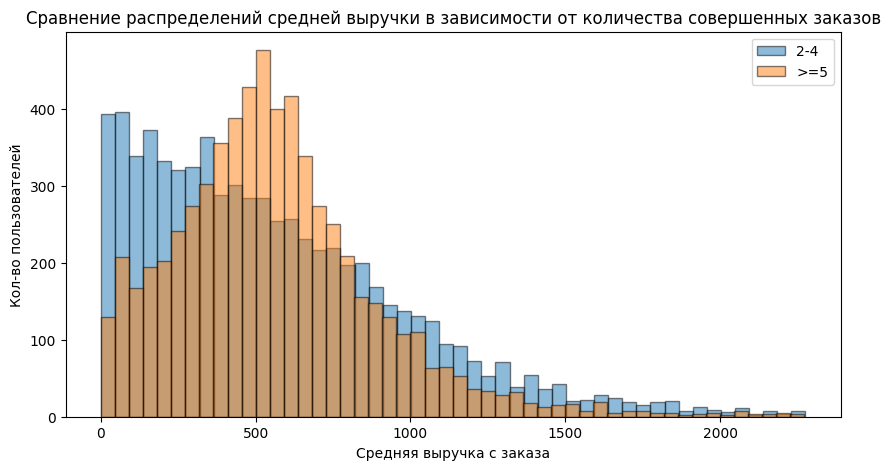

In [61]:
# Найдем пользователей, которые совершили от 5 заказов
more_4_orders = filtered_profile[filtered_profile['is_five'] == True] 

# Далее найдем пользователей, которые совершили от 2 до 4 заказов
in_range_2_to_4 = filtered_profile[(filtered_profile['is_two'] == True) & (filtered_profile['is_five'] == False)]

plt.figure(figsize=(10,5))

# Распределение для пользователей 2-4 заказа
in_range_2_to_4['avg_revenue_rub'].plot(
    kind='hist',
    bins=50,
    alpha=0.5,
    edgecolor='black',
)

# Распределение для пользователей >= 5
more_4_orders['avg_revenue_rub'].plot(
    kind='hist',
    bins=50,
    alpha=0.5,
    edgecolor='black',
)

plt.title('Сравнение распределений средней выручки в зависимости от количества совершенных заказов')
plt.xlabel('Средняя выручка с заказа')
plt.ylabel('Кол-во пользователей')
plt.legend(['2-4', '>=5'])


Распределения различаются.
- У пользователей с 2–4 заказами распределение не смещено влево. Пик приходится на дешевые заказы (до 100 руб.), но при этом количество людей, совершающих дорогие покупки (от 820 руб. и выше), в этой группе больше, чем в группе с 5+ заказами, следовательно, данная группа более склонна к дорогостоящим покупкам.
- У пользователей с 5 и более заказами пик смещен в средний ценовой сегмент — около 590 руб., а дорогие чеки встречаются реже, чем в первой группе.

Постоянные клиенты (5+ заказов) демонстрируют более стабильный и предсказуемый чек. Вторая группа более неоднородна, а значит и менее предсказуема.

---
Изучим распределение пользователей по среднему количеству билетов в заказе

Text(0, 0.5, 'Кол-во пользователей')

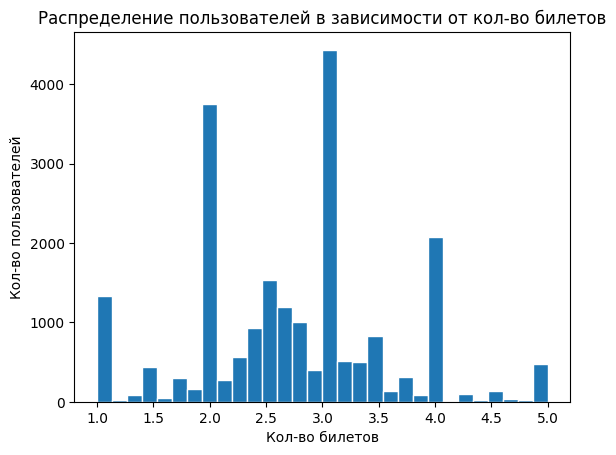

In [62]:
# Проводим фильтрацию по 99-му перцентилю 
filter_tickets = user_profile['avg_count_tickets'] <= user_profile['avg_count_tickets'].quantile(0.99)

filtered_profile = user_profile[filter_tickets]

filtered_profile['avg_count_tickets'].plot(
    kind='hist',
    bins=30,
    edgecolor='white'
)

plt.title('Распределение пользователей в зависимости от кол-во билетов')
plt.xlabel('Кол-во билетов')
plt.ylabel('Кол-во пользователей')

Основные наблюдения:
- больше всего пользователей, которые в среднем совершают покупку 2 и 3 билетов. Их количество составляет около 3700 и 4500 чел. соответственно.
- Также существуют относительно большие сегменты пользователей: 1, 2.5 и 4 билетов. Количество пользователей в данных сегментах варьируется в диапазоне от 1300 - 2100.


Далее проведем сегментацию пользователей:
- от 1 до 2 билетов;
- от 2 до 3 билетов;
- от 3 до 5 билетов;
- от 5 и более билетов.

In [63]:

from_1_to_2 = user_profile[user_profile['avg_count_tickets'].between(1,2, inclusive='left')]
from_2_to_3 = user_profile[user_profile['avg_count_tickets'].between(2,3, inclusive='left')] 
from_3_to_5 = user_profile[user_profile['avg_count_tickets'].between(3,5, inclusive='left')] 
from_5_and_more = user_profile[user_profile['avg_count_tickets'] >= 5] 

In [64]:
df_grouped = from_1_to_2.groupby('is_two').size()

C:\Users\semen\AppData\Local\Temp\ipykernel_15960\2281828977.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_grouped, palette='Set2')


Text(0, 0.5, 'Кол-во пользователей')

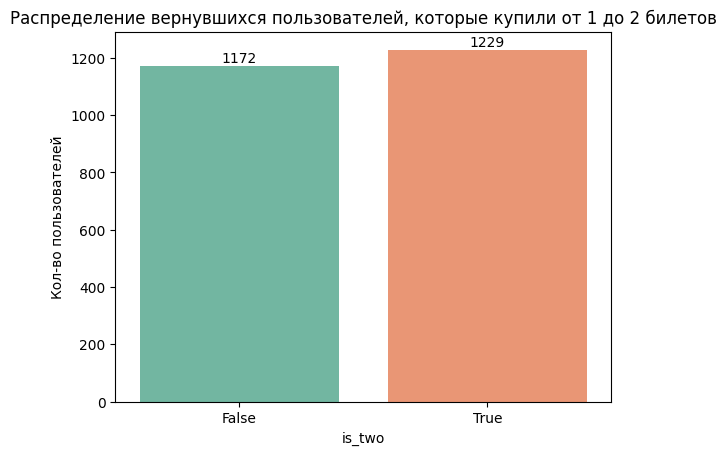

In [65]:
# создаем холст
ax = sns.barplot(data=df_grouped, palette='Set2')

# Добавляем подписи значений
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])

plt.title('Распределение вернувшихся пользователей, которые купили от 1 до 2 билетов')
plt.ylabel('Кол-во пользователей')

In [66]:
print(f'Всего пользователей: {df_grouped.sum()} чел. \n Доля вернувшихся: {round(df_grouped[True] * 100 / df_grouped.sum())}% ({df_grouped[True]} чел.)')

Всего пользователей: 2401 чел. 
 Доля вернувшихся: 51% (1229 чел.)


C:\Users\semen\AppData\Local\Temp\ipykernel_15960\3365391136.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_grouped, palette='Set2')


Text(0, 0.5, 'Кол-во пользователей')

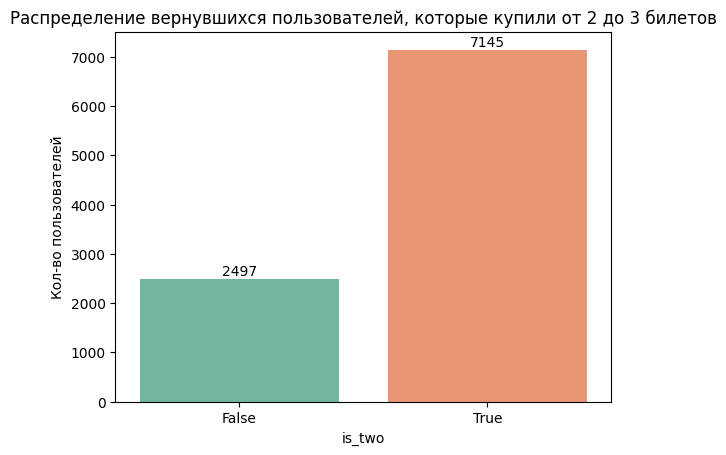

In [67]:
df_grouped = from_2_to_3.groupby('is_two').size()

# создаем холст
ax = sns.barplot(data=df_grouped, palette='Set2')

# Добавляем подписи значений
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])

plt.title('Распределение вернувшихся пользователей, которые купили от 2 до 3 билетов')
plt.ylabel('Кол-во пользователей')

In [68]:
print(f'Всего пользователей: {df_grouped.sum()} чел. \n Доля вернувшихся: {round(df_grouped[True] * 100 / df_grouped.sum())}% ({df_grouped[True]} чел.)')

Всего пользователей: 9642 чел. 
 Доля вернувшихся: 74% (7145 чел.)


C:\Users\semen\AppData\Local\Temp\ipykernel_15960\2801822322.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_grouped, palette='Set2')


Text(0, 0.5, 'Кол-во пользователей')

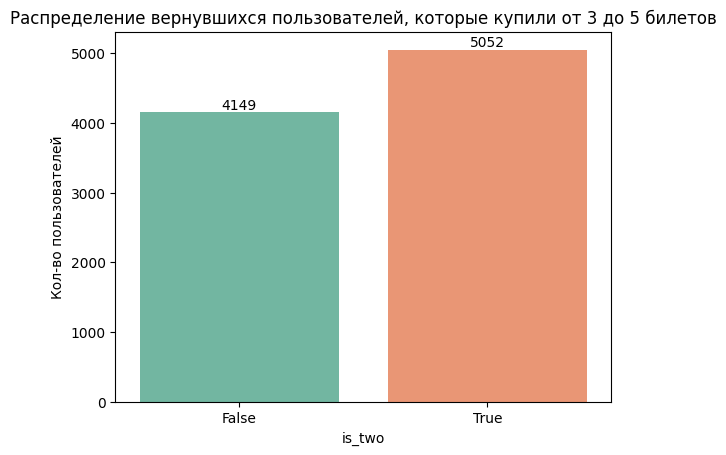

In [69]:
df_grouped = from_3_to_5.groupby('is_two').size()

# создаем холст
ax = sns.barplot(data=df_grouped, palette='Set2')

# Добавляем подписи значений
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])

plt.title('Распределение вернувшихся пользователей, которые купили от 3 до 5 билетов')
plt.ylabel('Кол-во пользователей')

In [70]:
print(f'Всего пользователей: {df_grouped.sum()} чел. \n Доля вернувшихся: {round(df_grouped[True] * 100 / df_grouped.sum())}% ({df_grouped[True]} чел.)')

Всего пользователей: 9201 чел. 
 Доля вернувшихся: 55% (5052 чел.)


C:\Users\semen\AppData\Local\Temp\ipykernel_15960\2396835469.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_grouped, palette='Set2')


Text(0, 0.5, 'Кол-во пользователей')

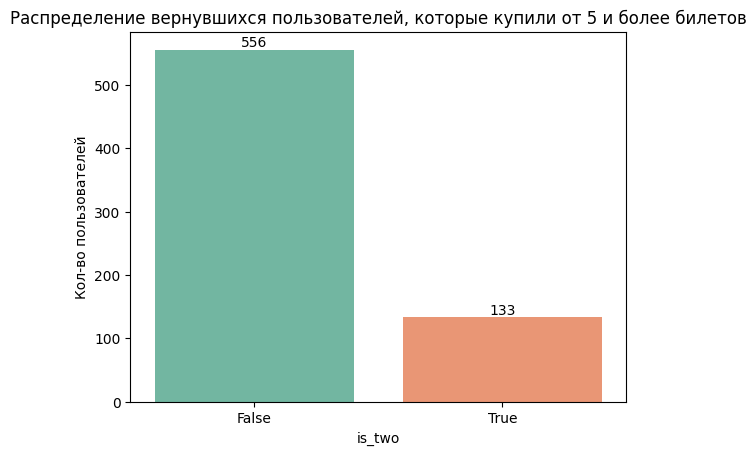

In [71]:
df_grouped = from_5_and_more.groupby('is_two').size()

# создаем холст
ax = sns.barplot(data=df_grouped, palette='Set2')

# Добавляем подписи значений
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])


plt.title('Распределение вернувшихся пользователей, которые купили от 5 и более билетов')
plt.ylabel('Кол-во пользователей')

In [72]:
print(f'Всего пользователей: {df_grouped.sum()} чел. \n Доля вернувшихся: {round(df_grouped[True] * 100 / df_grouped.sum())}% ({df_grouped[True]} чел.)')

Всего пользователей: 689 чел. 
 Доля вернувшихся: 19% (133 чел.)


Пользователи в каждом сегменте распределены неравномерно:
- В сегменте от 1 до 2 билетов: 2401 чел. с долей вернувшихся: 51% (1229 чел.)
- В сегменте от 2 до 3 билетов: 9642 чел. с долей вернувшихся: 74% (7145 чел.)
- В сегменте от 3 до 5 билетов: 9201 чел. с долей вернувшихся: 55% (5052 чел.)
- В сегменте от 5 билетов и более: 689 чел. с долей вернувшихся: 19% (133 чел.)

Как мы видим самый большой сегмент пользователей, которые купили от 2 включительно и 3  не включительно билетов, также он имеет самую большую долю вернувшихся клиентов, и как следствие постоянных клиентов, что говорит о хорошем уровне сервиса. Самый маленький сегмент - от 5 и более билетов, он аномально мал. 

Самый большой потенциал роста — в сегментах 1–2 билета и 3–5 билетов. У них достаточно большая аудитория, но доля возвратов (51% и 55%) значительно ниже, чем у группы 2–3 (74%). Маркетингу стоит направить усилия на удержание именно этих групп. Сегмент 5+ билетов не является приоритетным для массового удержания.

---
### Исследование временных характеристик первого заказа и их влияния на повторные покупки

Изучим временные параметры, связанные с первым заказом пользователей:
- день недели первой покупки;
- средний интервал между покупками пользователей с повторными заказами.

In [73]:
# Добавим новый столбец к профилю пользователя - номер дня недели
user_profile['week_number'] = user_profile['first_order_data'].map(lambda x: x.isoweekday())

Для экономии памяти, приведем данный столбец к типу `category`.

In [74]:
user_profile['week_number'] = user_profile['week_number'].astype('category')

Был добавлен новый столбец, в котором написан номер дня недели в нотации ISO. Рассмотрим распределение пользователей относительно этого номера.

Text(0, 0.5, 'Кол-во пользователей')

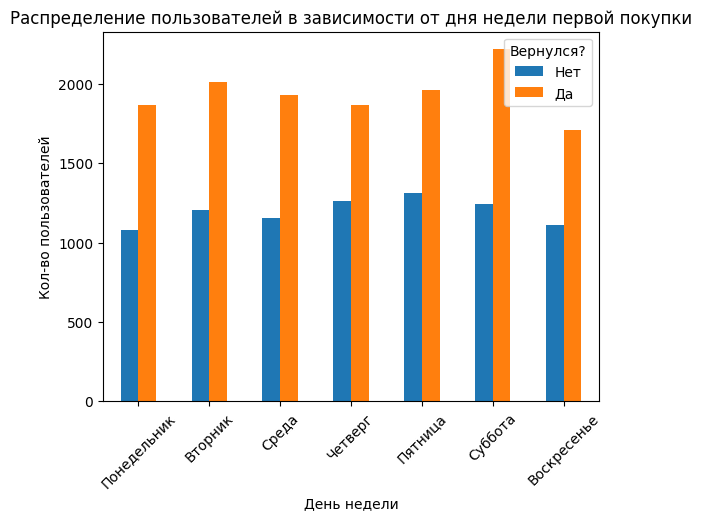

In [75]:
pivot_users = pd.pivot_table(
    user_profile,
    index='week_number',
    columns='is_two',
    values='first_order_data', # здесь можно взять любой не имеющий пропусков атрибут
    aggfunc='count'
)

pivot_users.rename(columns={True: 'Да', False: 'Нет'}, inplace=True)

ax = pivot_users.plot(
    kind='bar',
    rot=45
)

legend = ax.get_legend()
legend.set_title('Вернулся?')

plt.xticks(ticks=range(7), labels=['Понедельник', 'Вторник', 'Среда', 'Четверг', 'Пятница', 'Суббота', 'Воскресенье'])
plt.title('Распределение пользователей в зависимости от дня недели первой покупки')
plt.xlabel('День недели')
plt.ylabel('Кол-во пользователей')

In [76]:
pivot_users

is_two,Нет,Да
week_number,,
1,1079,1868
2,1208,2010
3,1157,1927
4,1265,1865
5,1312,1962
6,1242,2219
7,1111,1708


Из распределения видно, что:
- В понедельник первый заказ оформило - 2947 чел.
- Во вторник - 3218 чел.
- В среду - 3084 чел.
- В четверг - 3130 чел.
- В пятницу - 3274 чел.
- В субботу - 3461 чел.
- В воскресенье - 2819 чел.

Большинство людей совершили первый заказ в субботу, меньше всего в воскресенье, разница в пользователях составляет 642 чел.

Также:
- Больше всего вернувшихся пользователей в субботу (2219), что составляет 64% от числа пользователей в субботу(3461 чел.). 
- Наименьшее кол-во пользователей в воскресенье - 2819 чел, кол-во вернувшихся 1708 - 61%.
- Наименьшая доля вернувшихся пользователей приходится на четверг (1865 чел.) - 60%
- Разница между наибольшой и наименьшей долями составляет 4,5.

**Из наблюдений можно сделать вывод, что день недели почти не влияет на вероятность возврата пользователя.**

Также был добавлен новый столбец типа category, который показывает день недели даты первой покупки пользователя в нотации ISO.

---
Рассчитаем среднее время между заказами для двух групп пользователей:
- совершившие 2–4 заказа;
- совершившие 5 и более заказов

Text(0, 0.5, 'Кол-во пользователей')

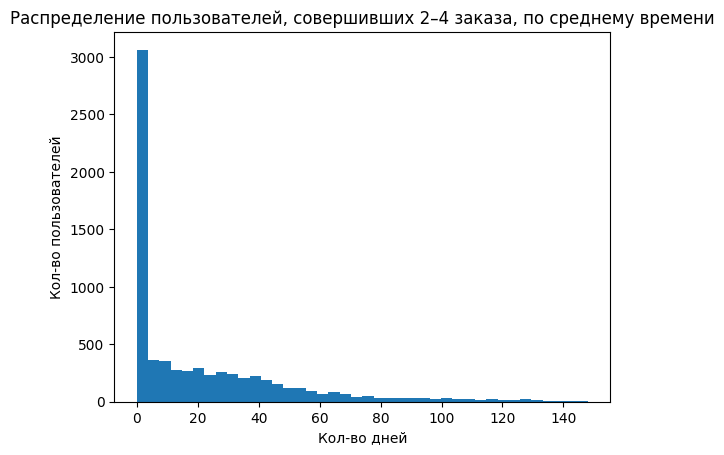

In [77]:
df_filtered = user_profile[(user_profile['is_two'] == True) & (user_profile['is_five'] == False)]['time_between_orders']

df_filtered.plot(
    kind='hist',
    bins=40
)

plt.title('Распределение пользователей, совершивших 2–4 заказа, по среднему времени')
plt.xlabel('Кол-во дней')
plt.ylabel('Кол-во пользователей')


In [78]:
print(f'Среднее время между заказами для пользователей, совершивших 2–4 заказа: {round(df_filtered.mean())} дней')
print(f'Медианное время: {round(df_filtered.median())} дней')
print(f'Самое частое время: {df_filtered.value_counts().index[0]} дней, которое встречалось {df_filtered.value_counts()[0]} раз')


Среднее время между заказами для пользователей, совершивших 2–4 заказа: 21 дней
Медианное время: 9 дней
Самое частое время: 0.0 дней, которое встречалось 2472 раз


Text(0, 0.5, 'Кол-во пользователей')

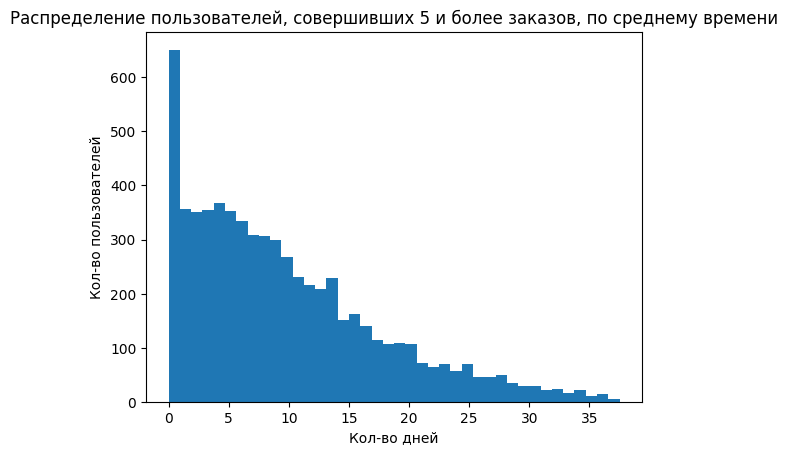

In [79]:
df_filtered = user_profile[user_profile['is_five'] == True]['time_between_orders']

df_filtered.plot(
    kind='hist',
    bins=40
)

plt.title('Распределение пользователей, совершивших 5 и более заказов, по среднему времени')
plt.xlabel('Кол-во дней')
plt.ylabel('Кол-во пользователей')

In [80]:
print(f'Среднее время между заказами для пользователей совершивших 5 и более заказов: {round(df_filtered.mean())} дней')
print(f'Медианное время: {round(df_filtered.median())} дней')
print(f'Самое частое время: {df_filtered.value_counts().index[0]} дней, которое встречалось {df_filtered.value_counts()[0]} раз')

Среднее время между заказами для пользователей совершивших 5 и более заказов: 10 дней
Медианное время: 8 дней
Самое частое время: 0.0 дней, которое встречалось 279 раз


Для обеих групп пользователей характерно совершение покупок в один день (мода = 0 дней), а медианный интервал между заказами составляет 8–9 дней.

Однако среднее время и форма распределения существенно различаются:
- У пользователей с 2–4 заказами ярко выражена правосторонняя асимметрия: при медиане в 9 дней среднее значение составляет 21 день. Это говорит о нестабильном поведении.
- У самых лояльных пользователей (5+ заказов) средний интервал почти в два раза меньше — 10 дней, а хвост распределения ограничивается 38 днями.

Пользователи, ставшие постоянными (5+ заказов), характеризуются значительно меньшим средним интервалом и меньшим разбросом. Это означает, что **короткий интервал коррелирует с переходом в категорию лояльных клиентов.**

---
### Корреляционный анализ количества покупок и признаков пользователя

Рассчитаем коэффициент корреляции phi_k между признаками профиля пользователя и числом заказов ( total_orders ).

Проверим, какое количество уникальных значений присутствует в колонках `first_region` и `first_service_name`.

In [81]:
for column in ['first_region', 'first_service_name']:
    print(f'{column}: {user_profile[column].nunique()}')

first_region: 81
first_service_name: 34


Количество значений не превышает 100, оставим без изменений. Интервальные колонки для подсчета:
- avg_revenue_rub 
- avg_count_tickets 
- time_between_orders
- total_orders

Для выявления данные параметры( сырые даты) **задействоватся не будут**:
- first_order_data
- last_order_data

Вместо данных атрибутов создадим новую колонку `lifetime`, которая будет отображать длительность жизненного цикла (в днях) с момента первой покупки и до последней.

In [82]:
# Создадим новую колонку lifetime с понижением разрядности
user_profile['lifetime'] = pd.to_numeric((user_profile['last_order_data'] - user_profile['first_order_data']).dt.days, downcast='integer')

In [83]:
# Создадим список интервальных колонок
interval_columns = ['avg_revenue_rub', 'avg_count_tickets', 'time_between_orders', 'total_orders', 'lifetime']
# Все колонки, которые будут задействованы в поиске корреляции 
useful_columns = interval_columns + ['first_device_type', 'first_region', 'first_service_name', 'first_event_type_main', 'is_two', 'is_five']


In [84]:
correlation_matrix = user_profile[useful_columns].phik_matrix(interval_cols=interval_columns)

Визуализируем полученные результаты 

In [85]:
data_heatmap = correlation_matrix[['total_orders']][correlation_matrix.index != 'total_orders'].sort_values(by='total_orders', ascending=False)

Text(0.5, 58.5815972222222, 'Общее число заказов клиента')

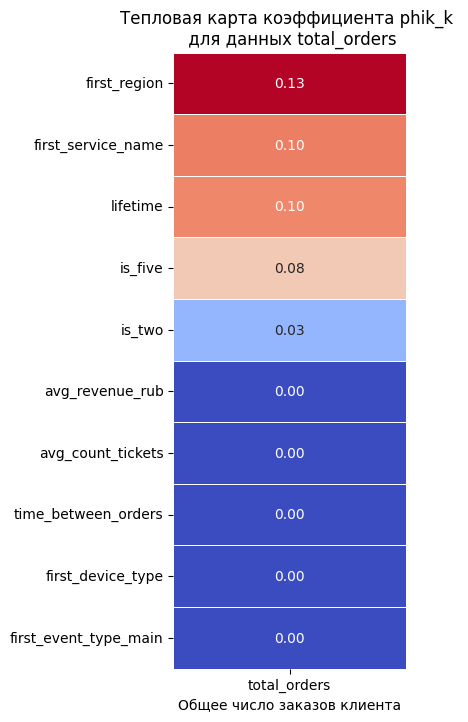

In [86]:
plt.figure(figsize=(3,8))

sns.heatmap(
    data_heatmap,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar=False
)

plt.title('Тепловая карта коэффициента phik_k \n для данных total_orders')
plt.xlabel('Общее число заказов клиента')

По полученным результатам можно сделать вывод:
- имеется 5 атрибутов, с которыми существует корреляция: регион, билетный оператор, жизненный цикл и параметры is_two и is_five. Наибольшая корреляция — с первым регионом (0.13), наименьшая — с is_two (0.03).
- Также имеется 5 параметров, у которых корреляции практически нет: средняя выручка, среднее число билетов, время между заказами, тип устройства и мероприятия.

Данные показывают слабую связь с количеством заказов, возможно, это связано с аномальными значениями:
- 10 251 заказ у одного пользователя
- отрицательные и нулевые значения в avg_revenue_rub
- экстремально высокий чек avg_revenue_rub 16 738.69 руб.
- time_between_orders выброс в 148 дней

Было принято решение провести фильтрацию по 99-му перцентилю для столбцов: `total_orders`, `avg_revenue_rub`, `time_between_orders` и дополнительно оставить в столбце `avg_revenue_rub` положительные числа.

In [87]:
# Создадим отфильтрованный профиль
columns = ['total_orders', 'avg_revenue_rub']
user_profile_filtered = user_profile
for column in columns:
    user_profile_filtered = user_profile_filtered[user_profile_filtered[column] <= user_profile_filtered[column].quantile(0.99)]

user_profile_filtered = user_profile_filtered[user_profile_filtered['avg_revenue_rub'] > 0]

**В моменте создания отфильтрованного профиля пользователя возникла проблема с фильтрацией по `time_between_orders`. Так как этот параметр имеет NaN значения, то любая фильтрация по этому полю будет работать некорректно.**

Для того чтобы посмотреть на реальную корреляцию **проведем сегментацию пользователей**:
- 1 заказ;
- от 2 до 4 заказов;
- от 5 и выше.

Во втором и третьем сегментах следует провести фильтрацию по `time_between_orders`. В этих сегментах NaN значения отсутствуют, все пропуски остались в первом сегменте.

In [88]:
filter_second_segment = (user_profile_filtered['total_orders'].isin([2,3,4])) & (user_profile_filtered['time_between_orders'] < user_profile_filtered['time_between_orders'].quantile(0.99) )
filter_third_segment = (user_profile_filtered['total_orders'] >= 5) & (user_profile_filtered['time_between_orders'] < user_profile_filtered['time_between_orders'].quantile(0.99) )

first_segment = user_profile_filtered[useful_columns][user_profile_filtered['total_orders'] == 1]
second_segment = user_profile_filtered[useful_columns][filter_second_segment]
third_segment = user_profile_filtered[useful_columns][filter_third_segment]

Также найдем размер каждого сегмента:

In [89]:
print(f'Размер первого сегмента: {first_segment.shape[0]} чел.')
print(f'Размер второго сегмента: {second_segment.shape[0]} чел.')
print(f'Размер третьего сегмента: {third_segment.shape[0]} чел.')

Размер первого сегмента: 8139 чел.
Размер второго сегмента: 6927 чел.
Размер третьего сегмента: 6141 чел.


Проведем корреляционный анализ для каждого сегмента:

In [90]:
correlation_matrix = first_segment.phik_matrix(interval_cols=interval_columns)

d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:72: UserWarning: Not enough unique value for variable time_between_orders for analysis 0. Dropping this column
  warnings.warn(
d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:72: UserWarning: Not enough unique value for variable total_orders for analysis 1. Dropping this column
  warnings.warn(
d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:72: UserWarning: Not enough unique value for variable lifetime for analysis 1. Dropping this column
  warnings.warn(
d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_five for analysis 1. Dropping this column
  warnings.warn(
d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_two for analysis 1. Dropping this column
  warnings.warn(


При расчете корреляционной матрицы для пользователей с одним заказом алгоритм phik выдал предупреждения и исключил из анализа целевую переменную total_orders, а также признаки is_two, is_five, time_between_orders и lifetime. Это ожидаемое поведение, а не ошибка кода. В данной группе все пользователи совершили ровно 1 заказ. Математически корреляция рассчитывается только для варьирующихся признаков. Поскольку целевая переменная не имеет разброса, **поиск зависимостей от нее в этом сегменте невозможен. Анализ корреляций имеет смысл только для сегментов с 2–4 и 5+ заказами.**

In [91]:
correlation_matrix = second_segment.phik_matrix(interval_cols=interval_columns)

d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_five for analysis 1. Dropping this column
  warnings.warn(
d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_two for analysis 1. Dropping this column
  warnings.warn(


При расчете матрицы корреляции для 2 сегмента **были удалены колонки** `is_two` и `is_five`, потому что в данном сегменте данные признаки приняли постоянные значения (для is_five везде False, для is_two везде True), поэтому дисперсия отсутствует.

Text(0.5, 58.5815972222222, 'Общее число заказов клиента')

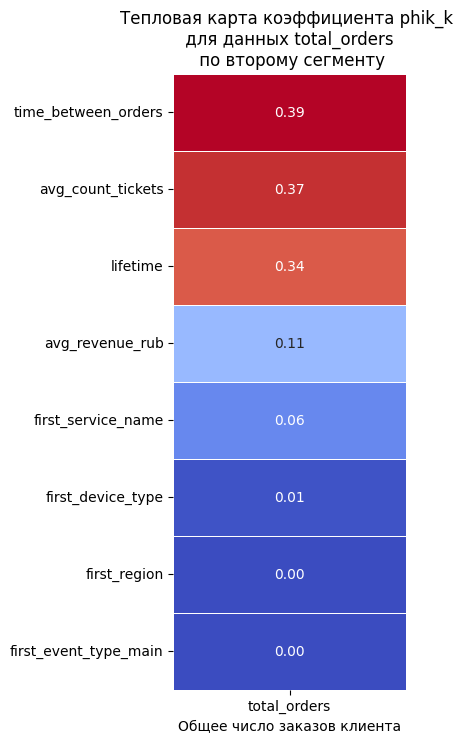

In [92]:
data_heatmap = correlation_matrix[['total_orders']][correlation_matrix.index != 'total_orders'].sort_values(by='total_orders', ascending=False)

plt.figure(figsize=(3,8))

sns.heatmap(
    data_heatmap,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar=False
)

plt.title('Тепловая карта коэффициента phik_k \n для данных total_orders \n по второму сегменту')
plt.xlabel('Общее число заказов клиента')

Наиболее **сильные** взаимосвязи:
- lifetime 0.34
- avg_count_tickets 0.37
- time_between_orders 0.39

Также присутствует очень **слабая** связь с:
- first_service_name 0.06 
- avg_revenue_rub 0.11
- first_device_type 0.01

Связь avg_count_tickets с total_orders (0.37) может объясняться как поведением пользователей, так и эффектом усреднения: при большем числе заказов среднее число билетов сильнее концентрируется около общего среднего. Также с количеством заказов может увеличиваться параметр `lifetime`. Наибольшую корреляцию показывает параметр `time_between_orders`, который стоит дополнительно изучить, так как он зависит от поведения пользователя.

Построим матрицу корреляции для 3 сегмента:

d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_five for analysis 1. Dropping this column
  warnings.warn(
d:\DS_Projects\yandex_afisha\my_venv\Lib\site-packages\phik\data_quality.py:82: UserWarning: Not enough unique value for variable is_two for analysis 1. Dropping this column
  warnings.warn(


Text(0.5, 58.5815972222222, 'Общее число заказов клиента')

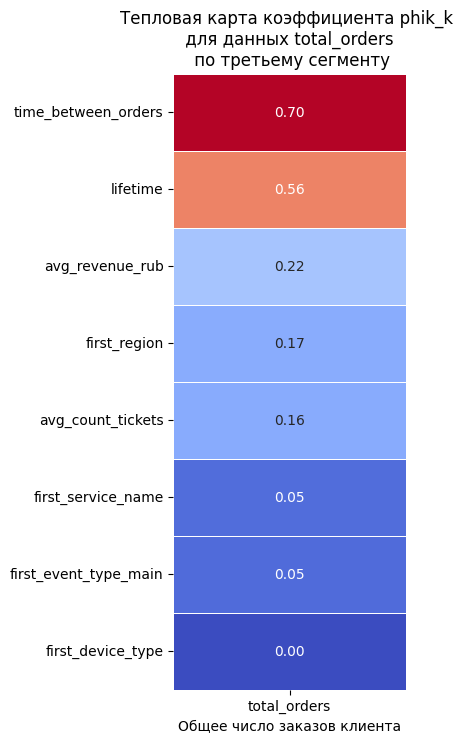

In [93]:
correlation_matrix = third_segment.phik_matrix(interval_cols=interval_columns)

data_heatmap = correlation_matrix[['total_orders']][correlation_matrix.index != 'total_orders'].sort_values(by='total_orders', ascending=False)

plt.figure(figsize=(3,8))

sns.heatmap(
    data_heatmap,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar=False
)

plt.title('Тепловая карта коэффициента phik_k \n для данных total_orders \n по третьему сегменту')
plt.xlabel('Общее число заказов клиента')

Также как и при построение матрицы была удалены колонки **были удалены колонки** `is_two` и `is_five`, потому что в данном сегменте данные признаки приняли постоянные значения.

В данном сегменте корреляция **более сильная**, чем в прошлом сегменте:
- time_between_orders 0.70
- lifetime 0.56

**Слабая** связь:
- avg_revenue_rub: 0.22
- first_region 0.17
- avg_count_tickets 0.16
- first_service_name 0.05
- first_event_type_main 0.05

В данном сегменте параметр `time_between_orders` имеет наибольшую связь, на 0.31 больше, чем во 2 сегменте. Параметр `lifetime` вырос на 0.22. Среднее количество билетов упало на 0.21.

---
### Промежуточный вывод

При проведении корреляционного анализа колонки `total_orders`:
- Создана новая колонка `lifetime` (в днях),отображающая длительность жизненного цикла клиента (от первой до последней покупки).
- Проведен общий анализ профилей пользователей, при котором найдена слабая связь(0.13) с параметром `first_region`
- Проведена сегментация пользователей: 1 заказ, от 2 до 4 заказов, от 5 и выше. Размеры сегментов составили: 8139, 6927 и 6141 человек соответственно.

**Первый сегмент не был рассмотрен**, так как алгоритм phik исключил целевую переменную total_orders из-за отсутствия вариативности (у всех пользователей ровно 1 заказ).Во 2 и 3 сегментах из матрицы были удалены признаки is_two и is_five, так как они приняли постоянные значения и не имели разброса.

Связь с `total_orders` в разрезе сегментов:
- Во втором сегменте наиболее сильная связь с `time_between_orders` (0.39) и `avg_count_tickets` (0.37).
- В третьем сегменте - `time_between_orders` (0.70), и средняя связь с `lifetime` (0.56).

Стоит учитывать,  что данные ограничены 5 месяцами (июнь–октябрь 2024), поэтому параметр `total_orders` больше всего коррелирует с `time_between_orders`: чем больше заказов сделал пользователь, тем меньше у него должно быть `time_between_orders`. Средняя корреляция с lifetime объясняется тем же — для большого числа заказов нужен длительный период активности.

**Для точного определения причинно-следственной связи следует провести анализ переменной time_between_orders в 2 и 3 сегментах.**

---
## Подведём итоги
В ходе исследования проанализировали данные 21 933 пользователей Яндекс Афиши за период 01.06.2024 – 31.10.2024. Данные включали информацию о заказах, мероприятиях и особенностях оплаты. Акцент исследования был на том, чтобы найти взаимосвязи между повторным заказом и другими факторами: типом первого мероприятия, типом устройства, регионом проведения мероприятия, билетным оператором, днём недели, лайфтаймом, средним интервалом между покупками и общим количеством покупок.

### Информация о данных
Профиль пользователя сформирован по 290 611 заказам. Ещё на этапе SQL-выгрузки были исключены мероприятия категории фильм и заказы с устройств, отличных от `mobile`/`desktop`, — из-за этого число уникальных пользователей сократилось с 22 000 до 21 933:
- Выручка заказов, оплаченных в тенге, переведена в рубли по дневному курсу за 2024 год.
- Найдены аномальные значения: отрицательная выручка (0.13% заказов), нулевая выручка (2% заказов), выбросы в числе заказов и интервалах между покупками. Значения не удалялись; фильтрация по 99-му перцентилю применялась только для визуализации и корреляционного анализа.
- Пропуски в days_since_prev (7.55%) не заполнялись — это первые заказы пользователей.

***Распределение пользователей по числу заказов:***
- 1 заказ — 38.2% пользователей;
- 2 и более заказа — 61.8%;
- 5 и более заказов — 29.2%.
Медианное число заказов на пользователя — 2.
Медианный средний чек клиента — 475 ₽, среднее число билетов в заказе — 2.8. У вернувшихся пользователей медианный интервал между заказами — 8 дней.

***Признаки первого заказа***
- Самый массовый сегмент по типу первого мероприятия — концерты: 44% пользователей.
- 83% пользователей совершили первый заказ с мобильного устройства.
- Топ-10 билетных операторов покрывают 90.3% пользователей. Самый массовый оператор — Билеты без проблем: у него наименьшая доля возвратов среди топ-10 (60.8%), но наибольшее абсолютное число вернувшихся — 3 182 чел.
- Топ-10 регионов покрывают 72% пользователей. Лидер по числу пользователей — Каменевский регион: 7 209 чел. (32.9%).

***Выручка и состав заказа***
- Пользователи, совершившие 2 и более заказа, имеют более высокий средний чек, чем пользователи с одним заказом.
- Пик распределения среднего чека по сегментам: 1 заказ — 0–45 ₽; 2–4 заказа — до 100 ₽; 5+ заказов — около 590 ₽.
- Пользователи с 5+ заказами более предсказуемы по чеку; пользователи с 2–4 заказами чаще совершают дорогостоящие покупки.
- Крупнейшие сегменты по среднему числу билетов в заказе: 2–3 билета — 9 642 чел., доля возвратов 74% (7 145 чел.); 3–5 билетов — 9 201 чел., 55% (5 052 чел.).

***Временные характеристики***
- День недели первой покупки почти не влияет на вероятность возврата.
- Для групп 2–4 и 5+ заказов характерны покупки в один день: самое частое значение среднего интервала в обеих группах — 0 дней.

***Корреляционный анализ***
- Наиболее сильная связь с числом заказов (total_orders) — у среднего интервала между заказами (time_between_orders): phi_k = 0.39 в сегменте 2–4 заказа и 0.70 в сегменте 5+. При окне наблюдения в 5 месяцев большее число заказов означает меньший средний интервал между ними.

### Факторы, связанные с возвратом пользователя
***Известны при первом заказе:***
- регион и тип мероприятия. Выше среднего возвращаются начавшие с театра и выставок, ниже — со спорта. Среди регионов выделяются Шанырский (лучший) и Озернинский край с Малиновоярским округом (худшие).
- билетный оператор, тип устройства, день недели первой покупки — различия между сегментами минимальны.

***Известны только после нескольких заказов:***
- Среднее число билетов в заказе: чаще всего возвращаются те, кто покупает 2–3 билета; покупающие по 5 и более билетов почти не возвращаются.
- Средний чек: у вернувшихся пользователей он заметно выше, чем у совершивших один заказ. Среди невернувшихся пользователей много клиентов с очень дешёвым единственным заказом.
- Интервал между заказами: постоянные клиенты покупают примерно вдвое чаще (в среднем раз в 10 дней против 21 дня у менее активных).
- Докупки в тот же день — типичное поведение обеих групп повторных покупателей.

### Рекомендации
- Провести программы удержания для сегментов по билетам 1–2 и 3–5.
- Провести углубленный анализ уровня сервиса в Озернинском крае и Малиновоярском округе и выяснить причины оттока
- Выяснить причины оттока по типу мероприятия спорт
- Создать предложения сразу после заказа.